# **Project Name**    - Bank Marketing Analysis using Hadoop, Hive and Spark (Distributed Machine Learning)

##### **Project Type**    - EDA / Classification
##### **Contribution**    - Individual
##### **Team Member 1 -** Manish


# **Project Summary -**

In this project I worked on the bank marketing dataset (`bank.csv`). It has 4,521 clients and 17 columns: age, job, marital status, education, balance, loans, contact details from the marketing campaign, and the target column `y`, which tells us whether the client subscribed to a term deposit.

Banks have a huge amount of customer data, and normal tools like Excel or plain pandas struggle with it. That is why tools like Hadoop, Hive and Spark are used. They split the data across many machines and process the pieces at the same time (in parallel). In this project I tried all the main parts of a distributed data pipeline on this dataset.

**1. Hadoop and Hive.** First I put the data into an HDFS-style folder. Then I wrote MapReduce programs in Python (a mapper and a reducer) to calculate things like the average balance for every job type, the number of housing loans per education level, and the number of clients contacted each month. Google Colab does not have a Hadoop cluster, so I ran the mapper and reducer the way Hadoop Streaming runs them (`cat | mapper | sort | reducer`). After that I created a Hive database `banking_data` with a table `client_info`, loaded the data, and answered the Hive questions with HiveQL queries.

**2. EDA with Spark.** I loaded the data into a Spark DataFrame and did filtering, groupBy, a UDF for age groups, string functions and Spark SQL queries. I made 15 charts. Some important findings:
* only 11.5% of clients subscribed, so the data is imbalanced,
* clients whose previous campaign was a success subscribed 64% of the time,
* retired clients and students have the highest subscription rates,
* May had the most calls but the lowest success rate,
* clients who subscribed had much longer calls.

I also did three hypothesis tests to check that these differences are real and not random.

**3. Machine learning with Spark ML.** I prepared the data:
* filled missing values,
* capped outliers,
* encoded categories with StringIndexer and OneHotEncoder,
* combined the features with VectorAssembler,
* scaled them,
* added class weights because of the imbalance.

I trained three models: Logistic Regression, Random Forest and Gradient-Boosted Trees. I tuned each one with ParamGridBuilder and CrossValidator and compared them using AUC, precision, recall and F1. I also tried a model without `duration`, because the call duration is only known after the call.

**4. Spark Streaming.** I split the data into small files and streamed them to simulate live bank transactions. I calculated live averages by job, made real-time predictions with my trained model, used 10-second and 1-minute windows, and used a watermark to handle late data.

**5. Data parallelism.** I checked the partitions, repartitioned the data, did calculations in parallel, compared training time with different numbers of partitions, monitored CPU and memory, and ran several tasks at the same time.

From this project I learned how distributed tools work together. HDFS stores the data, Hive gives SQL, Spark does fast analysis and ML, and Spark Streaming handles real-time data.

# **GitHub Link -**

Provide your GitHub Link here: `https://github.com/<your-username>/bank-distributed-ml`

# **Problem Statement**

**The bank calls customers to sell term deposits, but most customers say no (only about 11.5% say yes). This wastes a lot of time and money.**

The goal of this project is to:
1. store and query the bank data using Hadoop and Hive,
2. explore the data with Spark to find which customers are more likely to subscribe,
3. build a Spark ML model that predicts if a client will subscribe (`y` = yes/no),
4. process data in real time using Spark Streaming, and
5. use data parallelism to make processing faster.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.

             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.

[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.
U - Univariate Analysis, B - Bivariate Analysis, M - Multivariate Analysis ]

6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.

*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.
*   Cross- Validation & Hyperparameter Tuning
*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.
*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

# ***Let's Begin !***

## ***1. Know Your Data***

### Install PySpark and upload the dataset

In [ ]:
# Install pyspark (Colab sometimes already has it)
!pip install pyspark==3.5.3 -q

In [ ]:
# Upload bank.csv if it is not already in the Colab folder
import os
if not os.path.exists("bank.csv"):
    from google.colab import files
    files.upload()

print("File found:", os.path.exists("bank.csv"))

Saving bank.csv to bank.csv
File found: True


### Import Libraries

In [ ]:
# Import Libraries
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StringType

from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.stat import Correlation, ChiSquareTest
from pyspark.ml.functions import vector_to_array

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

In [ ]:
# Create a Spark session
# local[*] = use all CPU cores of this machine as workers
# enableHiveSupport() = lets us run Hive queries (HiveQL)
# FAIR scheduler = needed later for running tasks in parallel
spark = SparkSession.builder \
    .appName("BankProject") \
    .master("local[*]") \
    .config("spark.sql.shuffle.partitions", "8") \
    .config("spark.scheduler.mode", "FAIR") \
    .enableHiveSupport() \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)
print("Number of cores:", spark.sparkContext.defaultParallelism)

Spark version: 3.5.3
Number of cores: 2


### Dataset Loading

In [ ]:
# Load Dataset into a Spark DataFrame
df = spark.read.csv("bank.csv", header=True, inferSchema=True)
df.cache()   # keep it in memory because we use it many times

DataFrame[age: int, job: string, marital: string, education: string, default: string, balance: int, housing: string, loan: string, contact: string, day: int, month: string, duration: int, campaign: int, pdays: int, previous: int, poutcome: string, y: string]

### Dataset First View

In [ ]:
# Dataset First Look
df.show(5)

+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|        job|marital|education|default|balance|housing|loan| contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
| 30| unemployed|married|  primary|     no|   1787|     no|  no|cellular| 19|  oct|      79|       1|   -1|       0| unknown| no|
| 33|   services|married|secondary|     no|   4789|    yes| yes|cellular| 11|  may|     220|       1|  339|       4| failure| no|
| 35| management| single| tertiary|     no|   1350|    yes|  no|cellular| 16|  apr|     185|       1|  330|       1| failure| no|
| 30| management|married| tertiary|     no|   1476|    yes| yes| unknown|  3|  jun|     199|       4|   -1|       0| unknown| no|
| 59|blue-collar|married|secondary|     no|      0|    yes|  no| unknown|  5|  may|     22

### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count
print("Rows:", df.count())
print("Columns:", len(df.columns))

Rows: 4521
Columns: 17


### Dataset Information

In [ ]:
# Dataset Info
df.printSchema()

root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- balance: integer (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: integer (nullable = true)
 |-- month: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- y: string (nullable = true)



#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
print("Duplicate rows:", df.count() - df.dropDuplicates().count())

Duplicate rows: 0


#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show()

# This dataset uses the word 'unknown' instead of null, so let's count that too
cat_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
for c in cat_cols:
    print(c, ":", df.filter(F.col(c) == "unknown").count())

+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|age|job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|  0|  0|      0|        0|      0|      0|      0|   0|      0|  0|    0|       0|       0|    0|       0|       0|  0|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+

job : 38
marital : 0
education : 187
default : 0
housing : 0
loan : 0
contact : 1324
month : 0
poutcome : 3705


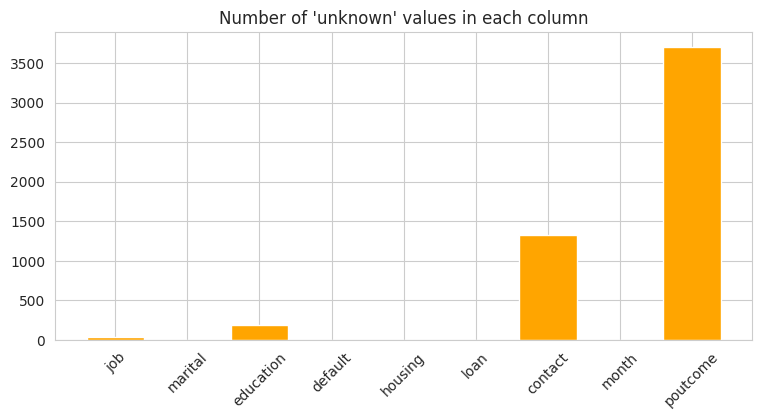

In [ ]:
# Visualizing the missing values ('unknown' counts)
unknown_counts = [df.filter(F.col(c) == "unknown").count() for c in cat_cols]
plt.figure(figsize=(9, 4))
plt.bar(cat_cols, unknown_counts, color="orange")
plt.title("Number of 'unknown' values in each column")
plt.xticks(rotation=45)
plt.show()

### What did you know about your dataset?

* There are **4,521 rows and 17 columns**.
* There are **no duplicates and no null values**.
* Missing information is written as **"unknown"**. `poutcome` has the most unknowns (3,705), because most clients were never contacted before. `contact` has 1,324.
* The target column `y` is **imbalanced**: only 521 clients (11.5%) said yes.
* `pdays = -1` means the client was never contacted before.
* `balance` and `duration` have some very large values (outliers).

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
print(df.columns)

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [ ]:
# Dataset Describe (only numeric columns)
num_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
df.select(num_cols).describe().show()

+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|               age|           balance|               day|          duration|          campaign|             pdays|          previous|
+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|              4521|              4521|              4521|              4521|              4521|              4521|              4521|
|   mean| 41.17009511170095|1422.6578190665782|15.915284229152842|263.96129174961294| 2.793629727936297|39.766644547666445|0.5425790754257908|
| stddev|10.576210958711263|3009.6381424673395| 8.247667327229934|259.85663262468216|3.1098066601885823|100.12112444301656|1.6935623506071211|
|    min|                19|             -3313|                 1|                 4|                 1|                -1|                 0|

### Variables Description

* **age** - age of the client
* **job** - type of job
* **marital** - married / single / divorced
* **education** - primary / secondary / tertiary / unknown
* **default** - does the client have credit in default?
* **balance** - average yearly account balance
* **housing** - does the client have a housing loan?
* **loan** - does the client have a personal loan?
* **contact** - how the client was contacted (cellular / telephone / unknown)
* **day, month** - day and month of the last contact
* **duration** - length of the last call in seconds
* **campaign** - number of calls in this campaign
* **pdays** - days since the last contact in a previous campaign (-1 = never)
* **previous** - number of contacts before this campaign
* **poutcome** - result of the previous campaign
* **y** - did the client subscribe to a term deposit? (**target**)

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.
for c in df.columns:
    print(c, ":", df.select(c).distinct().count())

age : 67
job : 12
marital : 3
education : 4
default : 2
balance : 2353
housing : 2
loan : 2
contact : 3
day : 31
month : 12
duration : 875
campaign : 32
pdays : 292
previous : 24
poutcome : 4
y : 2


## 3. ***Data Wrangling***

Here I answer the questions from the **Spark Data Processing (EDA)** document.

In [ ]:
# Q2a. Clients with balance greater than 1000
high_balance = df.filter(df.balance > 1000)
print("Clients with balance > 1000:", high_balance.count())
high_balance.show(5)

Clients with balance > 1000: 1481
+---+----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|       job|marital|education|default|balance|housing|loan| contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
| 30|unemployed|married|  primary|     no|   1787|     no|  no|cellular| 19|  oct|      79|       1|   -1|       0| unknown| no|
| 33|  services|married|secondary|     no|   4789|    yes| yes|cellular| 11|  may|     220|       1|  339|       4| failure| no|
| 35|management| single| tertiary|     no|   1350|    yes|  no|cellular| 16|  apr|     185|       1|  330|       1| failure| no|
| 30|management|married| tertiary|     no|   1476|    yes| yes| unknown|  3|  jun|     199|       4|   -1|       0| unknown| no|
| 39|  services|married|secondary|     no|   9374|    yes|  no|

In [ ]:
# Q2b. Convert month name to number, then make a quarter column
df = df.withColumn("month_num",
        F.when(df.month == "jan", 1).when(df.month == "feb", 2).when(df.month == "mar", 3)
         .when(df.month == "apr", 4).when(df.month == "may", 5).when(df.month == "jun", 6)
         .when(df.month == "jul", 7).when(df.month == "aug", 8).when(df.month == "sep", 9)
         .when(df.month == "oct", 10).when(df.month == "nov", 11).otherwise(12))

df = df.withColumn("quarter", F.concat(F.lit("Q"), F.ceil(df.month_num / 3).cast("string")))

# also a 1/0 column for subscribed, it makes calculating rates easy
df = df.withColumn("subscribed", F.when(df.y == "yes", 1).otherwise(0))

df.groupBy("quarter").agg(F.count("*").alias("clients"),
                          F.round(F.avg("subscribed") * 100, 2).alias("success_rate")).orderBy("quarter").show()

+-------+-------+------------+
|quarter|clients|success_rate|
+-------+-------+------------+
|     Q1|    419|        17.9|
|     Q2|   2222|        9.18|
|     Q3|   1391|       11.29|
|     Q4|    489|       17.38|
+-------+-------+------------+



In [ ]:
# Q3a. Average balance and median age for each job
df.groupBy("job").agg(F.round(F.avg("balance"), 2).alias("avg_balance"),
                      F.percentile_approx("age", 0.5).alias("median_age")) \
  .orderBy(F.desc("avg_balance")).show()

# Q3b. Number of clients who subscribed, for each marital status
df.filter(df.y == "yes").groupBy("marital").count().show()

+-------------+-----------+----------+
|          job|avg_balance|median_age|
+-------------+-----------+----------+
|      retired|    2319.19|        59|
|    housemaid|     2083.8|        49|
|   management|    1766.93|        38|
| entrepreneur|    1645.13|        41|
|      student|    1543.82|        26|
|      unknown|    1501.71|        49|
|self-employed|    1392.41|        40|
|   technician|     1331.0|        38|
|       admin.|    1226.74|        38|
|     services|    1103.96|        37|
|   unemployed|    1089.42|        41|
|  blue-collar|    1085.16|        39|
+-------------+-----------+----------+

+--------+-----+
| marital|count|
+--------+-----+
| married|  277|
|  single|  167|
|divorced|   77|
+--------+-----+



In [ ]:
# Q4. UDF to make age groups
def age_group(age):
    if age < 30:
        return "<30"
    elif age <= 60:
        return "30-60"
    else:
        return ">60"

age_group_udf = F.udf(age_group, StringType())
df = df.withColumn("age_group", age_group_udf(df.age))

df.groupBy("age_group").agg(F.count("*").alias("clients"),
                            F.round(F.avg("subscribed") * 100, 2).alias("subscription_rate")).show()

+---------+-------+-----------------+
|age_group|clients|subscription_rate|
+---------+-------+-----------------+
|    30-60|   3912|             10.2|
|      <30|    482|            15.35|
|      >60|    127|             37.8|
+---------+-------+-----------------+



In [ ]:
# Q5a. Subscription rate for each education level
df.groupBy("education").agg(F.round(F.avg("subscribed") * 100, 2).alias("subscription_rate")) \
  .orderBy(F.desc("subscription_rate")).show()

# Q5b. Top 3 jobs with the highest default rate
df.withColumn("is_default", F.when(df["default"] == "yes", 1).otherwise(0)) \
  .groupBy("job").agg(F.round(F.avg("is_default") * 100, 2).alias("default_rate")) \
  .orderBy(F.desc("default_rate")).show(3)

+---------+-----------------+
|education|subscription_rate|
+---------+-----------------+
| tertiary|             14.3|
|secondary|            10.62|
|  unknown|            10.16|
|  primary|             9.44|
+---------+-----------------+

+-------------+------------+
|          job|default_rate|
+-------------+------------+
| entrepreneur|        4.17|
|   unemployed|        2.34|
|self-employed|        2.19|
+-------------+------------+
only showing top 3 rows



In [ ]:
# Q6. String functions
df = df.withColumn("job_marital", F.concat_ws("_", df.job, df.marital))
df = df.withColumn("contact_upper", F.upper(df.contact))
df.select("job", "marital", "job_marital", "contact", "contact_upper").show(5)

+-----------+-------+-------------------+--------+-------------+
|        job|marital|        job_marital| contact|contact_upper|
+-----------+-------+-------------------+--------+-------------+
| unemployed|married| unemployed_married|cellular|     CELLULAR|
|   services|married|   services_married|cellular|     CELLULAR|
| management| single|  management_single|cellular|     CELLULAR|
| management|married| management_married| unknown|      UNKNOWN|
|blue-collar|married|blue-collar_married| unknown|      UNKNOWN|
+-----------+-------+-------------------+--------+-------------+
only showing top 5 rows



In [ ]:
# Q12. Spark SQL using a temporary view
df.createOrReplaceTempView("bank")

spark.sql("""
    SELECT age_group, ROUND(AVG(balance), 2) AS avg_balance
    FROM bank
    GROUP BY age_group
""").show()

spark.sql("""
    SELECT job, COUNT(*) AS clients
    FROM bank
    GROUP BY job
    ORDER BY clients DESC
    LIMIT 5
""").show()

+---------+-----------+
|age_group|avg_balance|
+---------+-----------+
|    30-60|    1426.88|
|      <30|     1058.1|
|      >60|    2676.35|
+---------+-----------+

+-----------+-------+
|        job|clients|
+-----------+-------+
| management|    969|
|blue-collar|    946|
| technician|    768|
|     admin.|    478|
|   services|    417|
+-----------+-------+



### What all manipulations have you done and insights you found?

**Manipulations:** filtered clients with balance > 1000, added `month_num`, `quarter`, `subscribed` (1/0), `age_group` (using a UDF), `job_marital` and `contact_upper`, and created a temporary view `bank` for Spark SQL.

**Insights:**
* 1,481 clients (about 33%) have a balance above 1,000.
* Q2 (Apr-Jun) has the most contacts (2,222) but only a 9.2% success rate. Q1 (17.9%) and Q4 (17.4%) are much better.
* Retired clients have the highest average balance (2,319), with a median age of 59.
* Married clients are the biggest group of subscribers (277), but single (14%) and divorced (14.6%) clients have a higher subscription rate than married ones (9.9%).
* Tertiary education has the highest subscription rate (14.3%).
* Entrepreneurs (4.2%), the unemployed (2.3%) and the self-employed (2.2%) have the highest default rates.
* Clients older than 60 subscribe a lot more (37.8%) than clients aged 30-60 (10.2%).

## ***3A. Hadoop: HDFS and MapReduce***

**HDFS** stores big files by cutting them into blocks and saving copies on many computers.
**MapReduce** processes the data in 3 steps:
1. **Map** - every row becomes a (key, value) pair, for example (job, balance)
2. **Shuffle & Sort** - all pairs with the same key are grouped together
3. **Reduce** - the values for each key are combined, for example into an average

Google Colab does not have a Hadoop cluster, so I made an HDFS-like folder and ran the mapper and reducer the way **Hadoop Streaming** runs them: `cat file | mapper | sort | reducer`. On a real Hadoop cluster the commands would be:
```
hdfs dfs -mkdir -p /user/banking/input
hdfs dfs -put bank.csv /user/banking/input/
hadoop jar hadoop-streaming.jar -mapper mapper.py -reducer reducer.py -input /user/banking/input -output /user/banking/output
```

### 1. Data Ingestion

In [ ]:
# Make an HDFS-style folder and copy the dataset into it
!mkdir -p hdfs/user/banking/input
!cp bank.csv hdfs/user/banking/input/
!ls -l hdfs/user/banking/input

total 368
-rw-r--r-- 1 root root 375542 Nov 10 14:57 bank.csv


### 2. MapReduce Program 1 - average balance for each job

In [ ]:
%%writefile mapper_job_balance.py
#!/usr/bin/env python3
# Mapper: print "job <TAB> balance" for every row
import sys
for line in sys.stdin:
    parts = line.strip().split(",")
    if parts[0] == "age":      # skip the header row
        continue
    job = parts[1]
    balance = parts[5]
    print(job + "\t" + balance)

Writing mapper_job_balance.py


In [ ]:
%%writefile reducer_avg.py
#!/usr/bin/env python3
# Reducer: input is sorted by key, so we add up values until the key changes
import sys
current_key = None
total = 0
count = 0
for line in sys.stdin:
    key, value = line.strip().split("\t")
    value = float(value)
    if key == current_key:
        total += value
        count += 1
    else:
        if current_key is not None:
            print(current_key + "\t" + str(round(total / count, 2)) + "\t" + str(count))
        current_key = key
        total = value
        count = 1
if current_key is not None:
    print(current_key + "\t" + str(round(total / count, 2)) + "\t" + str(count))

Writing reducer_avg.py


In [ ]:
# Run it: map -> sort -> reduce, and save the output like Hadoop does (part-00000)
!mkdir -p hdfs/user/banking/output/avg_balance_by_job
!cat hdfs/user/banking/input/bank.csv | python3 mapper_job_balance.py | sort | python3 reducer_avg.py > hdfs/user/banking/output/avg_balance_by_job/part-00000
!cat hdfs/user/banking/output/avg_balance_by_job/part-00000

admin.	1226.74	478
blue-collar	1085.16	946
entrepreneur	1645.12	168
housemaid	2083.8	112
management	1766.93	969
retired	2319.19	230
self-employed	1392.41	183
services	1103.96	417
student	1543.82	84
technician	1331.0	768
unemployed	1089.42	128
unknown	1501.71	38


### MapReduce Program 2 - housing loan count for each education

In [ ]:
%%writefile mapper_education_housing.py
#!/usr/bin/env python3
# Mapper: key = education,housing  value = 1
import sys
for line in sys.stdin:
    parts = line.strip().split(",")
    if parts[0] == "age":
        continue
    education = parts[3]
    housing = parts[6]
    print(education + "," + housing + "\t1")

Writing mapper_education_housing.py


In [ ]:
%%writefile reducer_count.py
#!/usr/bin/env python3
# Reducer: count how many times each key appears
import sys
current_key = None
count = 0
for line in sys.stdin:
    key, value = line.strip().split("\t")
    if key == current_key:
        count += int(value)
    else:
        if current_key is not None:
            print(current_key + "\t" + str(count))
        current_key = key
        count = int(value)
if current_key is not None:
    print(current_key + "\t" + str(count))

Writing reducer_count.py


In [ ]:
!cat hdfs/user/banking/input/bank.csv | python3 mapper_education_housing.py | sort | python3 reducer_count.py

primary,no	295
primary,yes	383
secondary,no	876
secondary,yes	1430
tertiary,no	687
tertiary,yes	663
unknown,no	104
unknown,yes	83


### MapReduce Program 3 - clients contacted each month and their subscription status

In [ ]:
%%writefile mapper_month_y.py
#!/usr/bin/env python3
# Mapper: key = month,y  value = 1
import sys
for line in sys.stdin:
    parts = line.strip().split(",")
    if parts[0] == "age":
        continue
    month = parts[10]
    y = parts[16]
    print(month + "," + y + "\t1")

Writing mapper_month_y.py


In [ ]:
!cat hdfs/user/banking/input/bank.csv | python3 mapper_month_y.py | sort | python3 reducer_count.py

apr,no	237
apr,yes	56
aug,no	554
aug,yes	79
dec,no	11
dec,yes	9
feb,no	184
feb,yes	38
jan,no	132
jan,yes	16
jul,no	645
jul,yes	61
jun,no	476
jun,yes	55
mar,no	28
mar,yes	21
may,no	1305
may,yes	93
nov,no	350
nov,yes	39
oct,no	43
oct,yes	37
sep,no	35
sep,yes	17


### 3. Data Analysis with MapReduce

In [ ]:
%%writefile mapper_poutcome_duration.py
#!/usr/bin/env python3
# Mapper: key = poutcome  value = duration
import sys
for line in sys.stdin:
    parts = line.strip().split(",")
    if parts[0] == "age":
        continue
    print(parts[15] + "\t" + parts[11])

Writing mapper_poutcome_duration.py


In [ ]:
# Average call duration for each previous campaign outcome (same average reducer as before)
!cat hdfs/user/banking/input/bank.csv | python3 mapper_poutcome_duration.py | sort | python3 reducer_avg.py

failure	254.38	490
other	273.83	197
success	338.64	129
unknown	262.1	3705


In [ ]:
%%writefile mapper_age_balance.py
#!/usr/bin/env python3
# Mapper: key = age group (20-29, 30-39, ...)  value = balance
import sys
for line in sys.stdin:
    parts = line.strip().split(",")
    if parts[0] == "age":
        continue
    age = int(parts[0])
    start = (age // 10) * 10
    print(str(start) + "-" + str(start + 9) + "\t" + parts[5])

Writing mapper_age_balance.py


In [ ]:
# Average balance for each age group -> shows the relationship between age and balance
!cat hdfs/user/banking/input/bank.csv | python3 mapper_age_balance.py | sort | python3 reducer_avg.py

10-19	393.5	4
20-29	1063.66	478
30-39	1298.15	1808
40-49	1474.69	1203
50-59	1547.42	854
60-69	2619.78	113
70-79	3280.87	47
80-89	2071.14	14


**MapReduce findings:**
* Retired (2,319), housemaid (2,084) and management (1,767) have the highest average balance. Blue-collar (1,085) has the lowest.
* More primary- and secondary-educated clients have a housing loan than not. Tertiary is about half and half.
* May has the most contacts (1,398) but only 93 said yes. October, December, March and September have few contacts but high success.
* Clients whose previous outcome was "success" had the longest calls (about 339 seconds).
* The average balance goes up with age: about 1,064 for ages 20-29 and about 2,620 for 60-69. Older clients have more money saved.

## ***3B. Hive***
Hive lets us use SQL (HiveQL) on data stored in Hadoop. Here I run the HiveQL through Spark's Hive support, which uses the same Hive statements.

### 1. Data Ingestion and Table Creation

In [ ]:
# Hive LOAD DATA loads the file as it is, so I remove the header line first
!tail -n +2 bank.csv > bank_noheader.csv
!head -3 bank_noheader.csv

30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no


In [ ]:
spark.sql("CREATE DATABASE IF NOT EXISTS banking_data")
spark.sql("USE banking_data")
spark.sql("DROP TABLE IF EXISTS client_info")

spark.sql("""
CREATE TABLE client_info (
    age INT, job STRING, marital STRING, education STRING, `default` STRING,
    balance INT, housing STRING, loan STRING, contact STRING, day INT, month STRING,
    duration INT, campaign INT, pdays INT, previous INT, poutcome STRING, y STRING
)
ROW FORMAT DELIMITED FIELDS TERMINATED BY ','
STORED AS TEXTFILE
""")

path = os.getcwd() + "/bank_noheader.csv"
spark.sql(f"LOAD DATA LOCAL INPATH '{path}' OVERWRITE INTO TABLE client_info")
spark.sql("DESCRIBE client_info").show()

+---------+---------+-------+
| col_name|data_type|comment|
+---------+---------+-------+
|      age|      int|   NULL|
|      job|   string|   NULL|
|  marital|   string|   NULL|
|education|   string|   NULL|
|  default|   string|   NULL|
|  balance|      int|   NULL|
|  housing|   string|   NULL|
|     loan|   string|   NULL|
|  contact|   string|   NULL|
|      day|      int|   NULL|
|    month|   string|   NULL|
| duration|      int|   NULL|
| campaign|      int|   NULL|
|    pdays|      int|   NULL|
| previous|      int|   NULL|
| poutcome|   string|   NULL|
|        y|   string|   NULL|
+---------+---------+-------+



### 2. Basic Data Exploration

In [ ]:
spark.sql("SELECT COUNT(*) AS total_clients FROM client_info").show()
spark.sql("SELECT * FROM client_info LIMIT 10").show()

+-------------+
|total_clients|
+-------------+
|         4521|
+-------------+

+---+-------------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|          job|marital|education|default|balance|housing|loan| contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+-------------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
| 30|   unemployed|married|  primary|     no|   1787|     no|  no|cellular| 19|  oct|      79|       1|   -1|       0| unknown| no|
| 33|     services|married|secondary|     no|   4789|    yes| yes|cellular| 11|  may|     220|       1|  339|       4| failure| no|
| 35|   management| single| tertiary|     no|   1350|    yes|  no|cellular| 16|  apr|     185|       1|  330|       1| failure| no|
| 30|   management|married| tertiary|     no|   1476|    yes| yes| unknown|  3|  jun|     199|       4|   -1|       0| unknown|

### 3. Data Filtering and Sorting

In [ ]:
# Married clients with a personal loan
married_loan = spark.sql("SELECT * FROM client_info WHERE marital = 'married' AND loan = 'yes'")
print("Count:", married_loan.count())
married_loan.show(5)

# Top 10 clients with the highest balance
spark.sql("SELECT job, marital, balance FROM client_info ORDER BY balance DESC LIMIT 10").show()

Count: 453
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|        job|marital|education|default|balance|housing|loan| contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
| 33|   services|married|secondary|     no|   4789|    yes| yes|cellular| 11|  may|     220|       1|  339|       4| failure| no|
| 30| management|married| tertiary|     no|   1476|    yes| yes| unknown|  3|  jun|     199|       4|   -1|       0| unknown| no|
| 43|   services|married|  primary|     no|    -88|    yes| yes|cellular| 17|  apr|     313|       1|  147|       2| failure| no|
| 31|blue-collar|married|secondary|     no|    360|    yes| yes|cellular| 29|  jan|      89|       1|  241|       1| failure| no|
| 40| management|married| tertiary|     no|    194|     no| yes|cellular| 29|  

### 4. Data Aggregation and Grouping

In [ ]:
spark.sql("""
    SELECT job, ROUND(AVG(age), 2) AS avg_age
    FROM client_info GROUP BY job ORDER BY avg_age DESC
""").show()

spark.sql("""
    SELECT education, COUNT(*) AS defaulted_clients
    FROM client_info WHERE `default` = 'yes'
    GROUP BY education
""").show()

+-------------+-------+
|          job|avg_age|
+-------------+-------+
|      retired|  61.87|
|      unknown|  48.11|
|    housemaid|  47.34|
| entrepreneur|  42.01|
|self-employed|  41.45|
|   unemployed|  40.91|
|   management|  40.54|
|  blue-collar|  40.16|
|       admin.|  39.68|
|   technician|  39.47|
|     services|  38.57|
|      student|  26.82|
+-------------+-------+

+---------+-----------------+
|education|defaulted_clients|
+---------+-----------------+
| tertiary|               17|
|secondary|               46|
|  primary|               10|
|  unknown|                3|
+---------+-----------------+



### 5. Complex Queries for Insights

In [ ]:
# Top 5 jobs by average balance + % of them who subscribed
spark.sql("""
    SELECT job,
           ROUND(AVG(balance), 2) AS avg_balance,
           ROUND(SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS percent_subscribed
    FROM client_info
    GROUP BY job
    ORDER BY avg_balance DESC
    LIMIT 5
""").show()

# Month with the most contacts and its success rate
spark.sql("""
    SELECT month, COUNT(*) AS contacts,
           ROUND(SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS success_rate
    FROM client_info
    GROUP BY month
    ORDER BY contacts DESC
    LIMIT 1
""").show()

+------------+-----------+------------------+
|         job|avg_balance|percent_subscribed|
+------------+-----------+------------------+
|     retired|    2319.19|             23.48|
|   housemaid|     2083.8|             12.50|
|  management|    1766.93|             13.52|
|entrepreneur|    1645.13|              8.93|
|     student|    1543.82|             22.62|
+------------+-----------+------------------+

+-----+--------+------------+
|month|contacts|success_rate|
+-----+--------+------------+
|  may|    1398|        6.65|
+-----+--------+------------+



### 6. Correlation Analysis

In [ ]:
spark.sql("SELECT ROUND(CORR(age, balance), 4) AS correlation FROM client_info").show()

+-----------+
|correlation|
+-----------+
|     0.0838|
+-----------+



### 7. Trend Analysis
The dataset does **not have a year column**, so a real year-over-year trend is not possible. Instead I looked at the trend across months.

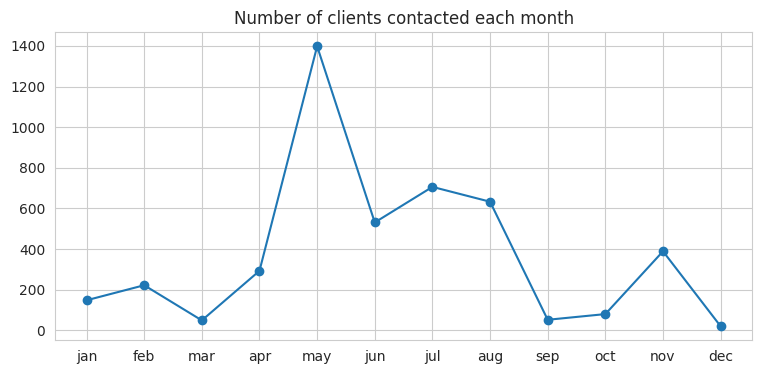

In [ ]:
monthly = spark.sql("""
    SELECT month, COUNT(*) AS contacts
    FROM client_info
    GROUP BY month
""").toPandas()

month_order = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
monthly["month"] = pd.Categorical(monthly["month"], categories=month_order, ordered=True)
monthly = monthly.sort_values("month")

plt.figure(figsize=(9, 4))
plt.plot(monthly["month"], monthly["contacts"], marker="o")
plt.title("Number of clients contacted each month")
plt.show()

### 8. Anomaly Detection

In [ ]:
# Average, median and standard deviation of balance for each education level
spark.sql("""
    SELECT education,
           ROUND(AVG(balance), 2) AS avg_balance,
           PERCENTILE_APPROX(balance, 0.5) AS median_balance,
           ROUND(STDDEV(balance), 2) AS std_balance,
           MAX(balance) AS max_balance
    FROM client_info
    GROUP BY education
    ORDER BY avg_balance DESC
""").show()

+---------+-----------+--------------+-----------+-----------+
|education|avg_balance|median_balance|std_balance|max_balance|
+---------+-----------+--------------+-----------+-----------+
| tertiary|    1775.42|           582|    3460.62|      42045|
|  unknown|    1701.25|           574|    2981.38|      21244|
|  primary|    1411.54|           403|    3713.76|      71188|
|secondary|    1196.81|           385|     2419.7|      26452|
+---------+-----------+--------------+-----------+-----------+



**Unusual pattern:** primary education has a higher average balance (1,412) than secondary (1,197), which is unexpected. Its median is only 405 and its standard deviation is the highest, so a few very rich clients are pulling the average up.

### 9. Advanced Analysis

In [ ]:
# Subscription rate for each previous campaign outcome
spark.sql("""
    SELECT poutcome,
           ROUND(SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS subscription_rate
    FROM client_info
    GROUP BY poutcome
    ORDER BY subscription_rate DESC
""").show()

# Average call duration: subscribed vs not subscribed
spark.sql("SELECT y, ROUND(AVG(duration), 2) AS avg_duration FROM client_info GROUP BY y").show()

+--------+-----------------+
|poutcome|subscription_rate|
+--------+-----------------+
| success|            64.34|
|   other|            19.29|
| failure|            12.86|
| unknown|             9.10|
+--------+-----------------+

+---+------------+
|  y|avg_duration|
+---+------------+
| no|      226.35|
|yes|      552.74|
+---+------------+



**Hive findings:**
* There are 4,521 clients. 453 married clients have a personal loan.
* The highest balance is 71,188 (a retired client).
* Retired clients are the oldest on average (about 62) and students the youngest (about 27).
* Secondary education has the most defaulters (46 of 76).
* Retired (23.5%) and students (22.6%) subscribe the most among the top balance jobs.
* May has the most contacts (1,398) but only a 6.7% success rate.
* The age and balance correlation is only 0.084, which is very weak.
* A previous campaign success leads to 64.3% subscription.
* Subscribers talk much longer: 553 seconds vs 226 seconds.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

I do the grouping in Spark and then convert the small result to pandas with `toPandas()` to plot it.

#### Chart - 1 : Target variable (y)

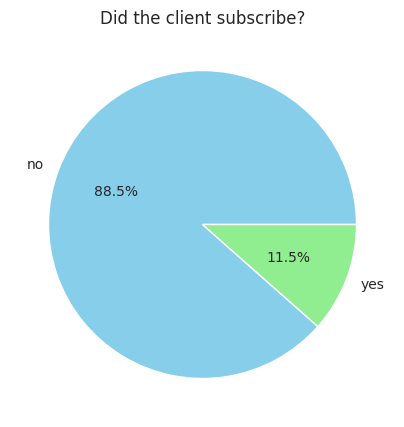

In [ ]:
# Chart - 1 visualization code
y_counts = df.groupBy("y").count().toPandas()
plt.figure(figsize=(5, 5))
plt.pie(y_counts["count"], labels=y_counts["y"], autopct="%1.1f%%", colors=["skyblue", "lightgreen"])
plt.title("Did the client subscribe?")
plt.show()

##### 1. Why did you pick the specific chart?

A pie chart is good for showing the share of each class in a yes/no column.

##### 2. What is/are the insight(s) found from the chart?

Only 11.5% of clients said yes and 88.5% said no. The data is very imbalanced.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows that most calls are wasted, so a model that finds the likely 'yes' clients can save a lot of time. The negative side is that the bank currently loses a lot of effort on clients who will say no.

#### Chart - 2 : Age distribution

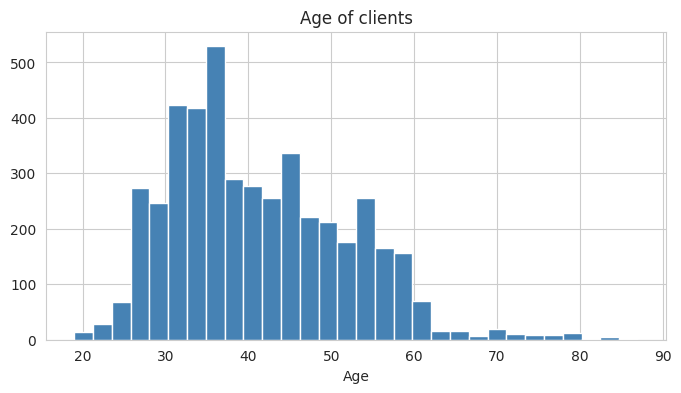

In [ ]:
# Chart - 2 visualization code
age_pd = df.select("age").toPandas()
plt.figure(figsize=(8, 4))
plt.hist(age_pd["age"], bins=30, color="steelblue", edgecolor="white")
plt.title("Age of clients")
plt.xlabel("Age")
plt.show()

##### 1. Why did you pick the specific chart?

A histogram shows how a numeric column is spread out.

##### 2. What is/are the insight(s) found from the chart?

Most clients are between 30 and 50 years old. The median age is 39. There are very few clients above 60.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Most calls go to people aged 30-50, but older clients (60+) actually subscribe more. Ignoring them because they are few would be a missed chance.

#### Chart - 3 : Balance distribution

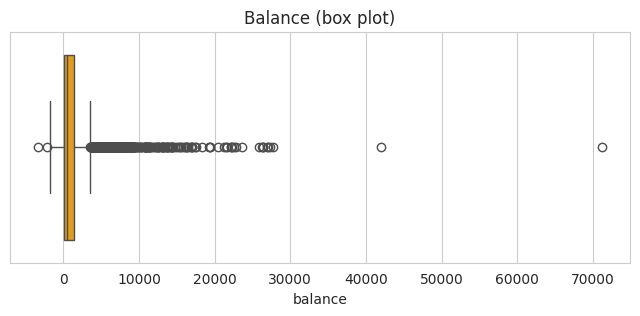

In [ ]:
# Chart - 3 visualization code
bal_pd = df.select("balance").toPandas()
plt.figure(figsize=(8, 3))
sns.boxplot(x=bal_pd["balance"], color="orange")
plt.title("Balance (box plot)")
plt.show()

##### 1. Why did you pick the specific chart?

A box plot clearly shows outliers.

##### 2. What is/are the insight(s) found from the chart?

Most balances are small (median 444), but there are many big outliers up to 71,188. 366 clients have a negative balance.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. High-balance clients are good targets for term deposits. Clients with a negative balance have no spare money, so calling them is not useful (negative impact).

#### Chart - 4 : Clients by job

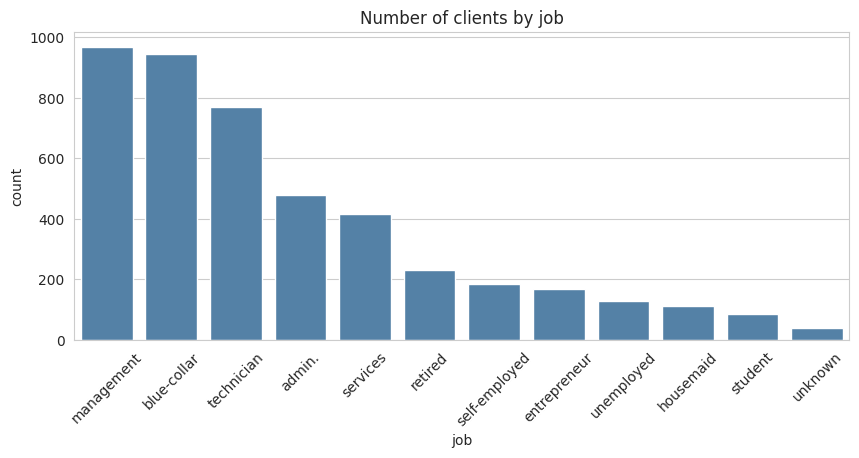

In [ ]:
# Chart - 4 visualization code
job_pd = df.groupBy("job").count().orderBy(F.desc("count")).toPandas()
plt.figure(figsize=(10, 4))
sns.barplot(data=job_pd, x="job", y="count", color="steelblue")
plt.title("Number of clients by job")
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is the easiest way to compare counts of categories.

##### 2. What is/are the insight(s) found from the chart?

Management (969), blue-collar (946) and technician (768) are the biggest groups. Students (84) and housemaids (112) are small groups.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows where most of the customers are. Blue-collar is a big group but has a low subscription rate (Chart 6), so spending many calls on it lowers success.

#### Chart - 5 : Call duration distribution

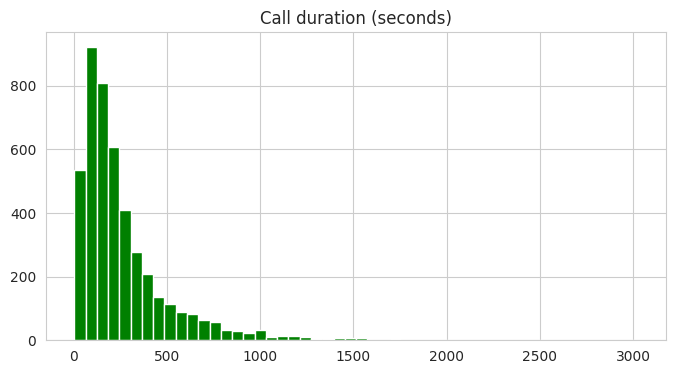

In [ ]:
# Chart - 5 visualization code
dur_pd = df.select("duration", "y").toPandas()
plt.figure(figsize=(8, 4))
plt.hist(dur_pd["duration"], bins=50, color="green")
plt.title("Call duration (seconds)")
plt.show()

##### 1. Why did you pick the specific chart?

A histogram shows the spread of call durations.

##### 2. What is/are the insight(s) found from the chart?

Most calls are short (median 185 seconds). A few calls are very long (up to 3,025 seconds). The data is right-skewed.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Longer calls usually mean the client is interested. But duration is only known after the call, so it can't be used to decide who to call.

#### Chart - 6 : Subscription rate by job

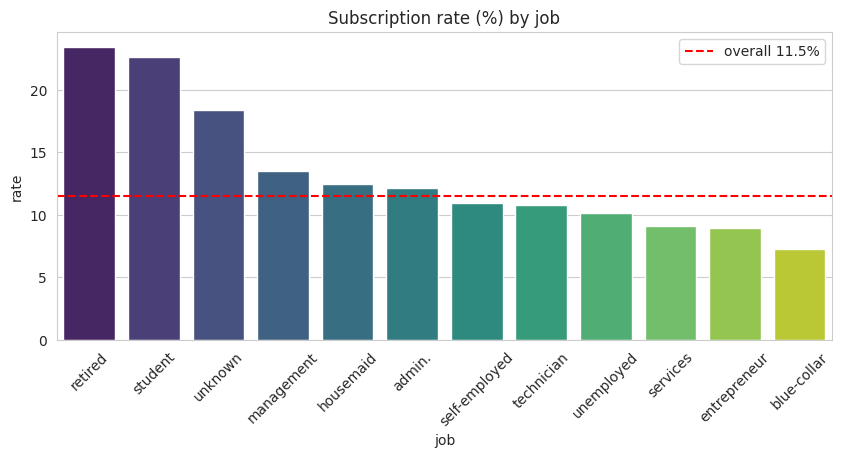

In [ ]:
# Chart - 6 visualization code
job_rate = df.groupBy("job").agg((F.avg("subscribed") * 100).alias("rate")).orderBy(F.desc("rate")).toPandas()
plt.figure(figsize=(10, 4))
sns.barplot(data=job_rate, x="job", y="rate", palette="viridis")
plt.axhline(11.5, color="red", linestyle="--", label="overall 11.5%")
plt.legend()
plt.title("Subscription rate (%) by job")
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of the rate compares groups fairly even when their sizes are different.

##### 2. What is/are the insight(s) found from the chart?

Retired (23.5%) and students (22.6%) have the highest rates. Blue-collar (7.3%) has the lowest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The bank should focus more on retired clients and students. Calling many blue-collar clients gives poor results (negative growth).

#### Chart - 7 : Contacts and success rate by month

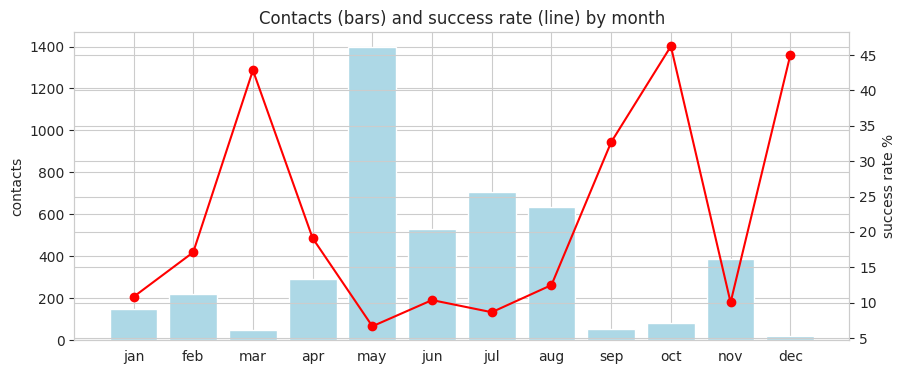

In [ ]:
# Chart - 7 visualization code
month_pd = df.groupBy("month", "month_num").agg(F.count("*").alias("contacts"),
                                                (F.avg("subscribed") * 100).alias("rate")).orderBy("month_num").toPandas()
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(month_pd["month"], month_pd["contacts"], color="lightblue")
ax1.set_ylabel("contacts")
ax2 = ax1.twinx()
ax2.plot(month_pd["month"], month_pd["rate"], color="red", marker="o")
ax2.set_ylabel("success rate %")
plt.title("Contacts (bars) and success rate (line) by month")
plt.show()

##### 1. Why did you pick the specific chart?

Bars plus a line let me show the number of contacts and the success rate together.

##### 2. What is/are the insight(s) found from the chart?

May has the most contacts (1,398) but the lowest success rate (6.7%). October (46%), December (45%), March (43%) and September (33%) have few contacts but high success.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The bank could move some calls from May to better months. Making so many calls in May with such low success is a negative pattern.

#### Chart - 8 : Duration vs subscription

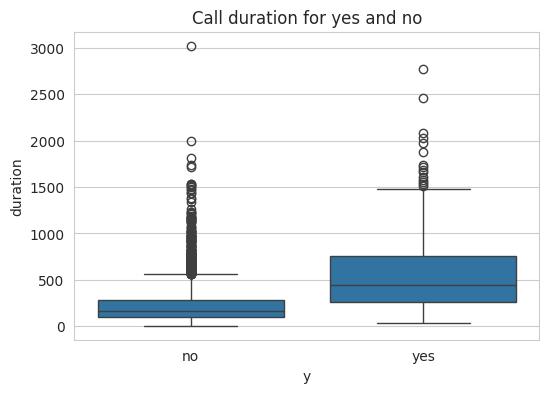

In [ ]:
# Chart - 8 visualization code
plt.figure(figsize=(6, 4))
sns.boxplot(data=dur_pd, x="y", y="duration")
plt.title("Call duration for yes and no")
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares a number between two groups.

##### 2. What is/are the insight(s) found from the chart?

Clients who said yes had much longer calls (average 553 seconds vs 226 seconds).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Agents can keep interested clients talking longer. Duration is only known after the call, though, so it can't be used before calling.

#### Chart - 9 : Age vs balance

Correlation between age and balance: 0.0838201422447774


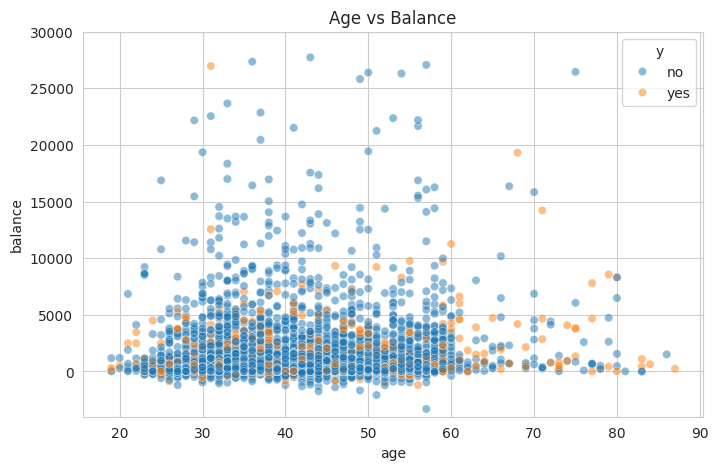

In [ ]:
# Chart - 9 visualization code
ab_pd = df.select("age", "balance", "y").toPandas()
print("Correlation between age and balance:", df.stat.corr("age", "balance"))
plt.figure(figsize=(8, 5))
sns.scatterplot(data=ab_pd, x="age", y="balance", hue="y", alpha=0.5)
plt.ylim(-4000, 30000)
plt.title("Age vs Balance")
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot shows the relationship between two numeric columns.

##### 2. What is/are the insight(s) found from the chart?

The correlation is only 0.084, so age and balance are almost unrelated. Older clients have slightly higher balances.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

It tells the bank not to guess a client's wealth just from their age. No direct negative impact.

#### Chart - 10 : Previous outcome vs subscription

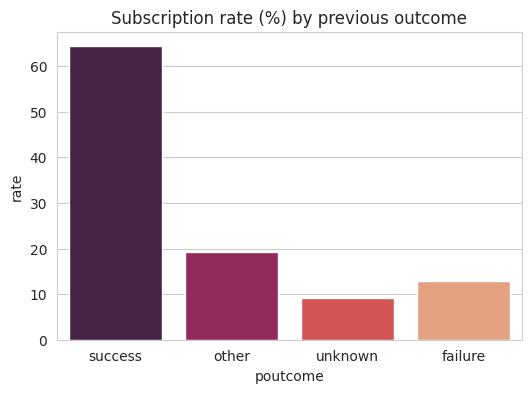

In [ ]:
# Chart - 10 visualization code
pout_pd = df.groupBy("poutcome").agg((F.avg("subscribed") * 100).alias("rate")).toPandas()
plt.figure(figsize=(6, 4))
sns.barplot(data=pout_pd, x="poutcome", y="rate", palette="rocket")
plt.title("Subscription rate (%) by previous outcome")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart compares the rate for each category.

##### 2. What is/are the insight(s) found from the chart?

If the previous campaign was a success, 64.3% subscribed again. Unknown (never contacted) is only 9.1%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Past successful clients should be called first. But this group is very small (129 clients), so the bank can't depend only on them.

#### Chart - 11 : Contact method

     contact       rate
0  telephone  14.617940
1    unknown   4.607251
2   cellular  14.364641


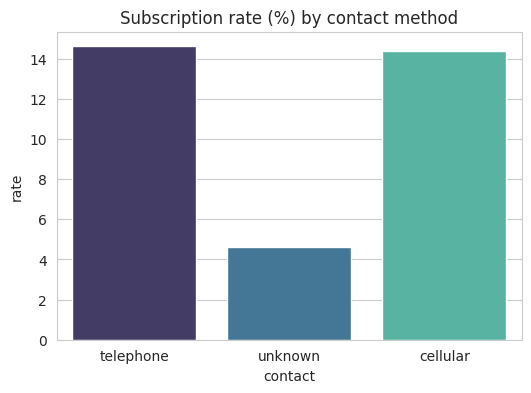

In [ ]:
# Chart - 11 visualization code
contact_pd = df.groupBy("contact").agg((F.avg("subscribed") * 100).alias("rate")).toPandas()
print(contact_pd)
plt.figure(figsize=(6, 4))
sns.barplot(data=contact_pd, x="contact", y="rate", palette="mako")
plt.title("Subscription rate (%) by contact method")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart directly shows which contact method works best.

##### 2. What is/are the insight(s) found from the chart?

Cellular (14.4%) and telephone (14.6%) are almost the same. 'Unknown' is only 4.6%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Recording proper phone numbers helps a lot. The 1,324 'unknown' contacts give very poor results, which is a negative impact.

#### Chart - 12 : Defaulters and loans

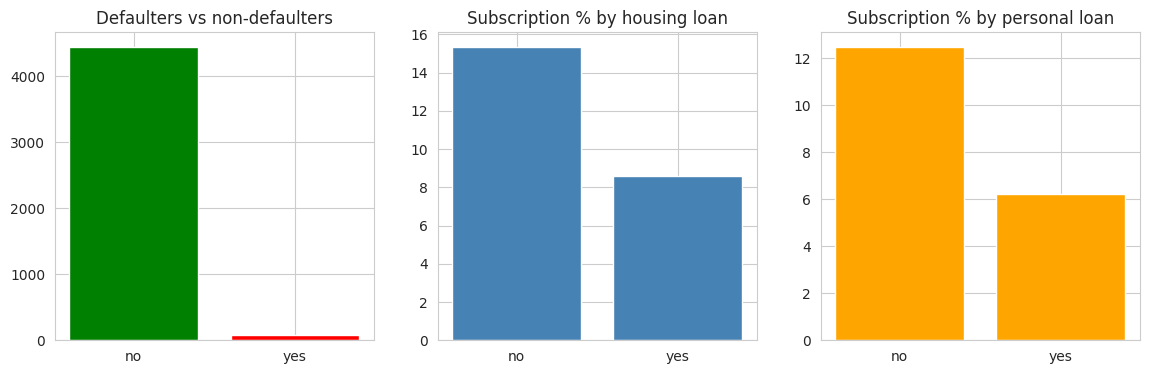

In [ ]:
# Chart - 12 visualization code
default_pd = df.groupBy("default").count().toPandas()
housing_pd = df.groupBy("housing").agg((F.avg("subscribed") * 100).alias("rate")).toPandas()
loan_pd = df.groupBy("loan").agg((F.avg("subscribed") * 100).alias("rate")).toPandas()

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].bar(default_pd["default"], default_pd["count"], color=["green", "red"])
ax[0].set_title("Defaulters vs non-defaulters")
ax[1].bar(housing_pd["housing"], housing_pd["rate"], color="steelblue")
ax[1].set_title("Subscription % by housing loan")
ax[2].bar(loan_pd["loan"], loan_pd["rate"], color="orange")
ax[2].set_title("Subscription % by personal loan")
plt.show()

##### 1. Why did you pick the specific chart?

Three small bar charts show the loan-related columns side by side.

##### 2. What is/are the insight(s) found from the chart?

Only 76 clients (1.7%) are defaulters. Clients without a housing loan subscribe more (15.3% vs 8.6%), and the same is true for personal loans (12.5% vs 6.2%).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Clients without loans have more free money, so they are better targets. Calling clients with loans or defaults gives low results.

#### Chart - 13 : Education + marital status (multivariate)

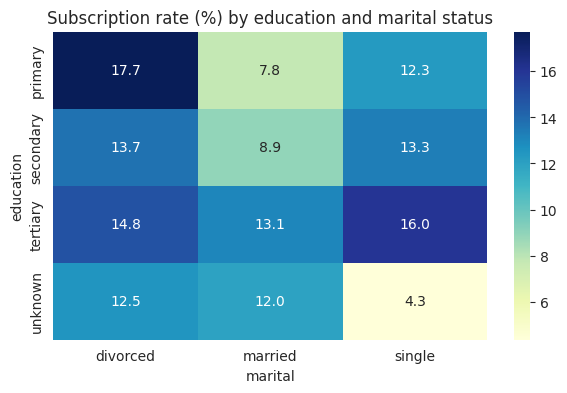

In [ ]:
# Chart - 13 visualization code
em = df.groupBy("education", "marital").agg((F.avg("subscribed") * 100).alias("rate")).toPandas()
table = em.pivot(index="education", columns="marital", values="rate")
plt.figure(figsize=(7, 4))
sns.heatmap(table, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Subscription rate (%) by education and marital status")
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap shows how two categories together affect the subscription rate.

##### 2. What is/are the insight(s) found from the chart?

Married clients have the lowest rates in every education group. Single tertiary (16%) and divorced primary (17.7%) are the highest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The bank can target single and divorced clients with higher education. Married clients with primary or secondary education are a big group with low results.

#### Chart - 14 - Correlation Heatmap

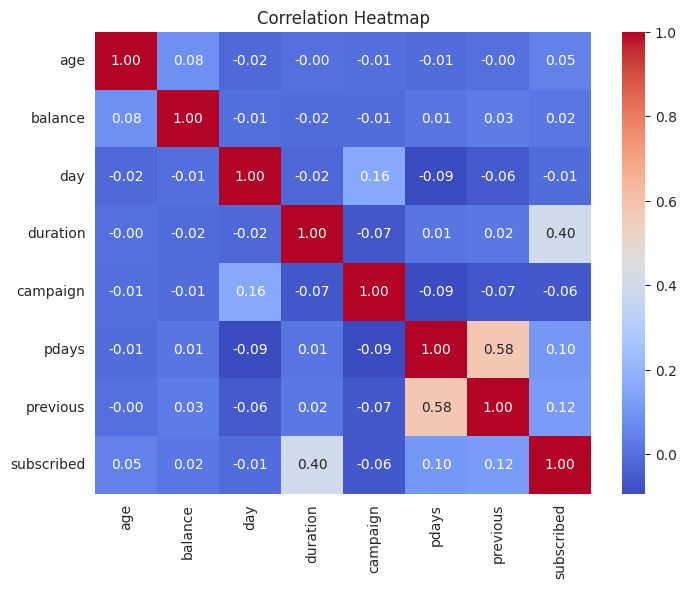

In [ ]:
# Correlation Heatmap visualization code
corr_pd = df.select(num_cols + ["subscribed"]).toPandas().corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_pd, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap shows the relationships between all the numeric columns at once.

##### 2. What is/are the insight(s) found from the chart?

Duration has the highest correlation with subscribing (0.40). pdays and previous are related to each other (0.58). The other columns are not strongly correlated, so there is no big multicollinearity problem.

#### Chart - 15 - Pair Plot

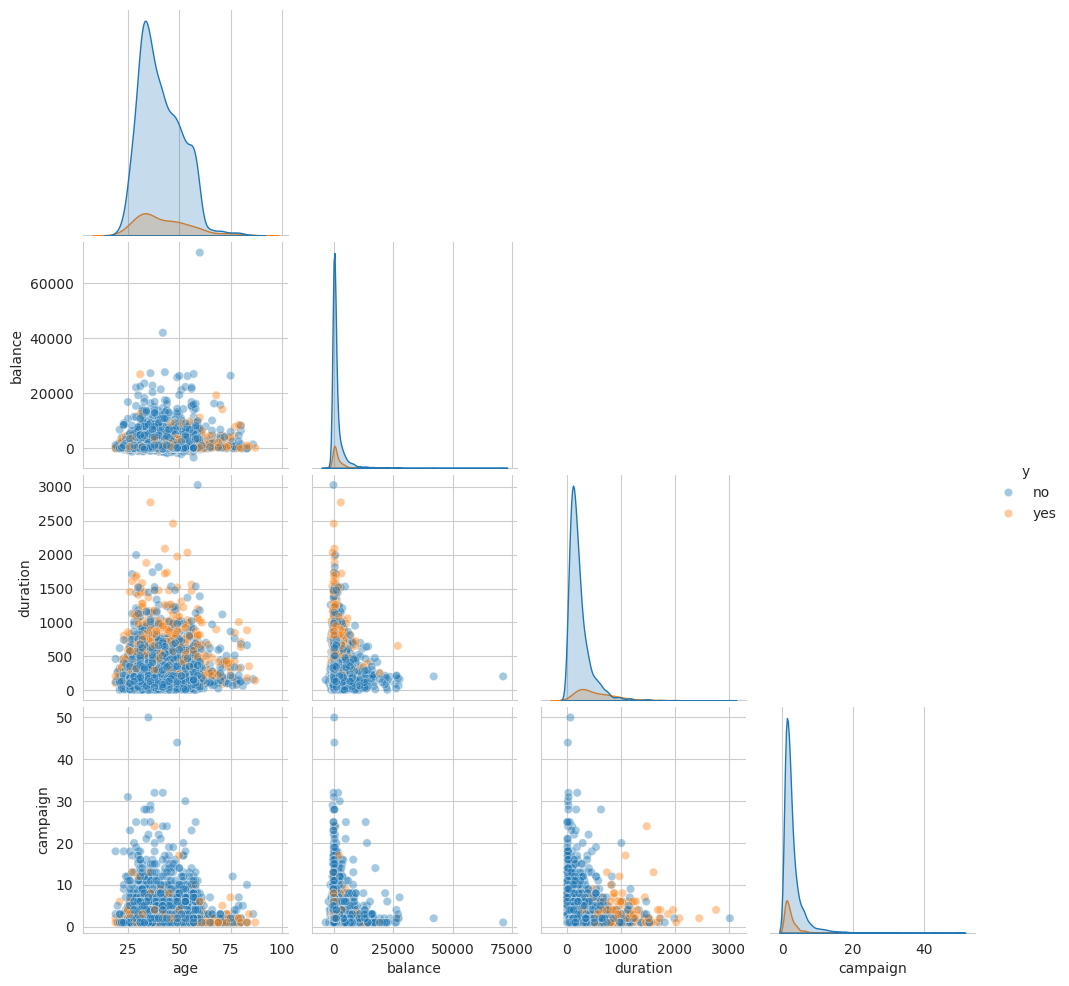

In [ ]:
# Pair Plot visualization code
pair_pd = df.select("age", "balance", "duration", "campaign", "y").toPandas()
sns.pairplot(pair_pd, hue="y", corner=True, plot_kws={"alpha": 0.4})
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every pair of numeric columns and how yes/no are spread.

##### 2. What is/are the insight(s) found from the chart?

Only duration clearly separates yes and no. People who subscribed were usually called only 1-3 times. Age and balance overlap a lot between the two groups.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

1. Clients who subscribed have a longer call duration.
2. Subscription depends on the contact method.
3. Subscription depends on having a housing loan.

In [ ]:
# For the statistical tests I convert the data to pandas (it is small)
pdf = df.toPandas()

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** Average duration is the same for yes and no.
* **H1:** Average duration is different for yes and no.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value
yes_dur = pdf[pdf["y"] == "yes"]["duration"]
no_dur = pdf[pdf["y"] == "no"]["duration"]
t_stat, p_value = stats.ttest_ind(yes_dur, no_dur, equal_var=False)
print("t-statistic:", t_stat)
print("p-value:", p_value)
if p_value < 0.05:
    print("Reject H0 -> duration is different")
else:
    print("Fail to reject H0")

t-statistic: 18.735946438313963
p-value: 3.605790464717552e-61
Reject H0 -> duration is different


##### Which statistical test have you done to obtain P-Value?

Welch's t-test. The p-value is almost 0, so I reject H0. People who subscribed really do have longer calls.

##### Why did you choose the specific statistical test?

I am comparing the average of a number (duration) between two groups. The groups have different sizes and variances, so Welch's t-test is the right choice.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** Subscription does not depend on the contact method.
* **H1:** Subscription depends on the contact method.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value
table = pd.crosstab(pdf["contact"], pdf["y"])
print(table)
chi2, p_value, dof, expected = stats.chi2_contingency(table)
print("Chi-square:", chi2, " p-value:", p_value)
if p_value < 0.05:
    print("Reject H0 -> contact method matters")
else:
    print("Fail to reject H0")

y            no  yes
contact             
cellular   2480  416
telephone   257   44
unknown    1263   61
Chi-square: 87.86985650165812  p-value: 8.30430129641147e-20
Reject H0 -> contact method matters


In [ ]:
# Same test done in a distributed way using Spark ML's ChiSquareTest
temp = StringIndexer(inputCol="contact", outputCol="contact_idx").fit(df).transform(df)
temp = VectorAssembler(inputCols=["contact_idx"], outputCol="contact_vec").transform(temp)
temp = temp.withColumn("label_d", F.col("subscribed").cast("double"))
ChiSquareTest.test(temp, "contact_vec", "label_d").show(truncate=False)

+-------+----------------+-------------------+
|pValues|degreesOfFreedom|statistics         |
+-------+----------------+-------------------+
|[0.0]  |[2]             |[87.86985650165812]|
+-------+----------------+-------------------+



##### Which statistical test have you done to obtain P-Value?

The chi-square test of independence, in both SciPy and Spark. The p-value is very small, so I reject H0. The contact method matters.

##### Why did you choose the specific statistical test?

Both columns are categorical, and the chi-square test is used to check whether two categorical columns are related.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** Subscription does not depend on having a housing loan.
* **H1:** Subscription depends on having a housing loan.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value
table = pd.crosstab(pdf["housing"], pdf["y"])
print(table)
chi2, p_value, dof, expected = stats.chi2_contingency(table)
print("Chi-square:", chi2, " p-value:", p_value)
if p_value < 0.05:
    print("Reject H0 -> housing loan matters")
else:
    print("Fail to reject H0")

y          no  yes
housing           
no       1661  301
yes      2339  220
Chi-square: 48.88462833144263  p-value: 2.7146998959323014e-12
Reject H0 -> housing loan matters


##### Which statistical test have you done to obtain P-Value?

The chi-square test. The p-value is very small, so I reject H0. Clients without a housing loan subscribe more (15.3% vs 8.6%).

##### Why did you choose the specific statistical test?

Both columns (housing and y) are categorical, so the chi-square test is the right test.

## ***6. Feature Engineering & Data Pre-processing***

In [ ]:
# Start from the original columns and add a numeric label column (yes = 1, no = 0)
data = spark.read.csv("bank.csv", header=True, inferSchema=True)
data = data.withColumn("label", F.when(data.y == "yes", 1.0).otherwise(0.0))

# Split into train (80%) and test (20%) first, so the test data stays unseen
train_raw, test_raw = data.randomSplit([0.8, 0.2], seed=42)
print("Train rows:", train_raw.count())
print("Test rows:", test_raw.count())

Train rows: 3662
Test rows: 859


### 1. Handling Missing Values

In [ ]:
# Handling Missing Values & Missing Value Imputation
# There are no nulls, but just in case: fill numbers with the median and text with 'unknown'
medians = {}
for c in num_cols:
    medians[c] = int(train_raw.approxQuantile(c, [0.5], 0.01)[0])
print("Medians:", medians)

Medians: {'age': 39, 'balance': 451, 'day': 16, 'duration': 184, 'campaign': 2, 'pdays': -1, 'previous': 0}


#### What all missing value imputation techniques have you used and why did you use those techniques?

There are no null values, but I still fill numeric columns with the **median** (the data is skewed, and the median is not affected by outliers) and text columns with **'unknown'**. I keep 'unknown' as its own category because it has meaning: for example, 'unknown' contact has a very low success rate.

### 2. Handling Outliers

In [ ]:
# Handling Outliers & Outlier treatments
# I cap (limit) balance and campaign at the 1st and 99th percentile
balance_low, balance_high = train_raw.approxQuantile("balance", [0.01, 0.99], 0.01)
campaign_low, campaign_high = train_raw.approxQuantile("campaign", [0.01, 0.99], 0.01)
print("Balance limits:", balance_low, balance_high)
print("Campaign limits:", campaign_low, campaign_high)

Balance limits: -3313.0 71188.0
Campaign limits: 1.0 50.0


##### What all outlier treatment techniques have you used and why did you use those techniques?

I used **capping** at the 1st and 99th percentiles. I did not delete the outlier rows because they are real clients (rich clients and clients called many times). Deleting them would lose information. I did not cap duration, because long calls are exactly where most of the 'yes' clients are.

### 3. Feature Manipulation (new features, transformation, capping)

In [ ]:
# One function with all the row-level steps, so I can use the SAME steps on
# train data, test data, streaming data and new clients
def prepare(d):
    d = d.fillna(medians)
    d = d.fillna("unknown")
    # capping outliers
    d = d.withColumn("balance_capped", F.when(d.balance > balance_high, balance_high)
                                        .when(d.balance < balance_low, balance_low)
                                        .otherwise(d.balance))
    d = d.withColumn("campaign_capped", F.when(d.campaign > campaign_high, campaign_high)
                                         .otherwise(d.campaign))
    # log transform for duration (it is right-skewed)
    d = d.withColumn("duration_log", F.log1p(d.duration))
    # new feature: was the client contacted before? (pdays = -1 means no)
    d = d.withColumn("contacted_before", F.when(d.pdays == -1, 0).otherwise(1))
    # new feature: total number of loans
    d = d.withColumn("total_loans", F.when(d.housing == "yes", 1).otherwise(0) +
                                    F.when(d.loan == "yes", 1).otherwise(0))
    return d

train = prepare(train_raw)
test = prepare(test_raw)
train.select("balance", "balance_capped", "duration", "duration_log", "pdays", "contacted_before", "total_loans").show(5)

+-------+--------------+--------+-----------------+-----+----------------+-----------+
|balance|balance_capped|duration|     duration_log|pdays|contacted_before|total_loans|
+-------+--------------+--------+-----------------+-----+----------------+-----------+
|    103|         103.0|     104|4.653960350157523|   -1|               0|          0|
|    302|         302.0|     205|5.327876168789581|   -1|               0|          0|
|   1169|        1169.0|     463|6.139884552226255|   -1|               0|          0|
|    291|         291.0|     172|5.153291594497779|  371|               1|          0|
|    502|         502.0|     261|5.568344503761097|   -1|               0|          0|
+-------+--------------+--------+-----------------+-----+----------------+-----------+
only showing top 5 rows



### 4. Categorical Encoding

In [ ]:
# Encode your categorical columns
# StringIndexer: text -> number,  OneHotEncoder: number -> 0/1 vector
indexer = StringIndexer(inputCols=cat_cols,
                        outputCols=[c + "_index" for c in cat_cols],
                        handleInvalid="keep")
encoder = OneHotEncoder(inputCols=[c + "_index" for c in cat_cols],
                        outputCols=[c + "_vec" for c in cat_cols])

#### What all categorical encoding techniques have you used & why did you use those techniques?

I used **StringIndexer** to change text to numbers and then **OneHotEncoder** to make 0/1 columns. One-hot encoding is needed because job, month and the other categories have no order: blue-collar is not 'bigger' than management. `handleInvalid='keep'` means a new category the model has never seen will not cause an error.

### 5. Textual Data Preprocessing

**Not needed.** This dataset has no text columns (like reviews or tweets). All columns are numbers or short categories, so steps like removing stopwords, tokenization and lemmatization do not apply.

### 6. Feature Selection

In [ ]:
# Select your features wisely to avoid overfitting
# Check how much each numeric feature is correlated with the label
for c in ["age", "balance_capped", "duration_log", "campaign_capped", "pdays", "previous", "day",
          "contacted_before", "total_loans"]:
    print(c, ":", round(train.stat.corr(c, "label"), 3))

age : 0.046
balance_capped : 0.012
duration_log : 0.34
campaign_capped : -0.06
pdays : 0.095
previous : 0.116
day : -0.009
contacted_before : 0.156
total_loans : -0.129


In [ ]:
feature_num_cols = ["age", "balance_capped", "duration_log", "campaign_capped", "pdays",
                    "previous", "day", "contacted_before", "total_loans"]
feature_cols = feature_num_cols + [c + "_vec" for c in cat_cols]
print("Number of input columns:", len(feature_cols))

Number of input columns: 18


##### What all feature selection methods have you used  and why?

I checked the correlation of each numeric feature with the label, and the correlation heatmap (Chart 14), to make sure no features are copies of each other. The categorical features were all significant in my chi-square tests. I kept all of them because there are only a few features, and tree models can pick the useful ones themselves. I used the capped/log versions instead of the raw balance, duration and campaign.

##### Which all features you found important and why?

**duration** (longer calls mean interest), **poutcome** (previous success), **month**, **contact**, **contacted_before / pdays**, **housing / loan** and **job / age**. These came out as important in the EDA charts and later in the model's feature importance.

### 7. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes. Duration is right-skewed, so I used a **log transform** (`log1p`) to make it more normal. Balance was capped instead because it has negative values, and log does not work on negative numbers.

### 8. Data Scaling

In [ ]:
# Scaling your data
assembler = VectorAssembler(inputCols=feature_cols, outputCol="raw_features", handleInvalid="keep")
scaler = StandardScaler(inputCol="raw_features", outputCol="features")

# Put all preprocessing steps in one pipeline and fit it on the training data only
prep_pipeline = Pipeline(stages=[indexer, encoder, assembler, scaler])
prep_model = prep_pipeline.fit(train)

train_data = prep_model.transform(train)
test_data = prep_model.transform(test)
train_data.select("features", "label").show(3, truncate=60)

+------------------------------------------------------------+-----+
|                                                    features|label|
+------------------------------------------------------------+-----+
|(53,[0,1,2,3,4,6,19,22,26,28,31,32,34,38,49],[1.794777669...|  1.0|
|(53,[0,1,2,3,4,6,19,22,24,28,31,32,34,38,49],[1.794777669...|  1.0|
|(53,[0,1,2,3,4,6,19,22,27,28,31,32,34,43,49],[1.794777669...|  0.0|
+------------------------------------------------------------+-----+
only showing top 3 rows



##### Which method have you used to scale you data and why?

**StandardScaler**, so all features are on a similar scale. This matters for Logistic Regression: without scaling, a column like pdays (0-871) would be treated very differently from a 0/1 column.

### 9. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No. After one-hot encoding there are only around 50 features, which is small for Spark. PCA would also make the model harder to explain.

### 10. Data Splitting

##### What data splitting ratio have you used and why?

I used **80% train / 20% test** with `randomSplit(seed=42)`. 80% gives the model enough examples to learn from, especially the few 'yes' rows, and 20% (around 900 rows) is enough for testing.

### 11. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes. Only 11.5% of the rows are 'yes'. A model could just say 'no' every time, be 88.5% accurate, and still be useless.

In [ ]:
# Handling Imbalanced Dataset: give more weight to the 'yes' rows
yes_ratio = train_data.filter("label = 1").count() / train_data.count()
print("Ratio of yes in train:", round(yes_ratio, 3))

train_data = train_data.withColumn("weight",
                F.when(F.col("label") == 1, 1 - yes_ratio).otherwise(yes_ratio))
train_data.groupBy("label", "weight").count().show()

Ratio of yes in train: 0.115
+-----+------------------+-----+
|label|            weight|count|
+-----+------------------+-----+
|  1.0|0.8847624249044238|  422|
|  0.0|0.1152375750955762| 3240|
+-----+------------------+-----+



##### What technique did you use to handle the imbalance dataset and why?

I used **class weights**: the 'yes' rows get a bigger weight, so the model pays more attention to them. This is easier than oversampling, and no data is removed or copied.

## ***7. ML Model Implementation***

In [ ]:
# A function to calculate all the metrics, so I don't repeat the same code 3 times
auc_eval = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")
pr_eval = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderPR")

def get_metrics(pred):
    tp = pred.filter("label = 1 AND prediction = 1").count()
    tn = pred.filter("label = 0 AND prediction = 0").count()
    fp = pred.filter("label = 0 AND prediction = 1").count()
    fn = pred.filter("label = 1 AND prediction = 0").count()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return {"AUC": auc_eval.evaluate(pred),
            "PR_AUC": pr_eval.evaluate(pred),
            "Accuracy": (tp + tn) / (tp + tn + fp + fn),
            "Precision": precision,
            "Recall": recall,
            "F1": f1}

results = {}   # I will store the scores of every model here

### ML Model - 1 : Logistic Regression

In [ ]:
# ML Model - 1 Implementation
lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="weight")

# Fit the Algorithm
lr_model = lr.fit(train_data)

# Predict on the model
lr_pred = lr_model.transform(test_data)
results["Logistic Regression"] = get_metrics(lr_pred)
print(results["Logistic Regression"])

{'AUC': 0.8925571504518891, 'PR_AUC': 0.47372920047375633, 'Accuracy': 0.8311990686845169, 'Precision': 0.3883495145631068, 'Recall': 0.8080808080808081, 'F1': 0.5245901639344263}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

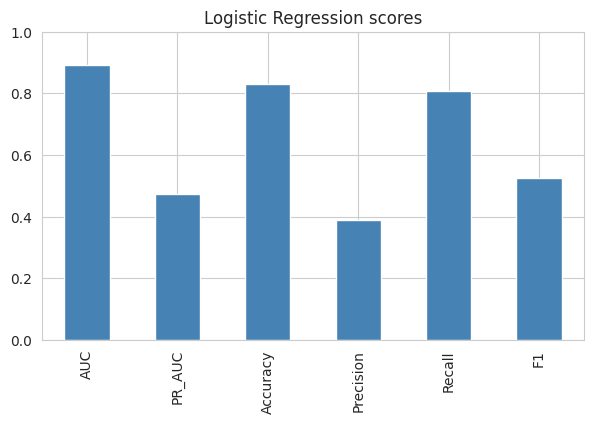

In [ ]:
# Visualizing evaluation Metric Score chart
pd.Series(results["Logistic Regression"]).plot(kind="bar", color="steelblue", figsize=(7, 4))
plt.title("Logistic Regression scores")
plt.ylim(0, 1)
plt.show()

Logistic Regression gives each feature a weight and turns the total into a probability of 'yes'. It is simple and fast, and it is a good first model. The AUC is around 0.9, which is good. Recall is high (it finds most of the 'yes' clients), but precision is lower because, with the class weights, it predicts 'yes' more often.

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
# ML Model - 1 Implementation with hyperparameter optimization techniques
lr_grid = ParamGridBuilder() \
    .addGrid(lr.regParam, [0.0, 0.01, 0.1]) \
    .addGrid(lr.elasticNetParam, [0.0, 0.5]) \
    .build()

lr_cv = CrossValidator(estimator=lr, estimatorParamMaps=lr_grid, evaluator=pr_eval,
                       numFolds=3, parallelism=2, seed=42)

# Fit the Algorithm
lr_cv_model = lr_cv.fit(train_data)

# Predict on the model
lr_cv_pred = lr_cv_model.transform(test_data)
results["Logistic Regression (tuned)"] = get_metrics(lr_cv_pred)
print("Best regParam:", lr_cv_model.bestModel.getOrDefault("regParam"))
print("Best elasticNetParam:", lr_cv_model.bestModel.getOrDefault("elasticNetParam"))
print(results["Logistic Regression (tuned)"])

Best regParam: 0.01
Best elasticNetParam: 0.0
{'AUC': 0.8911483253588528, 'PR_AUC': 0.4726238293436077, 'Accuracy': 0.8311990686845169, 'Precision': 0.3883495145631068, 'Recall': 0.8080808080808081, 'F1': 0.5245901639344263}


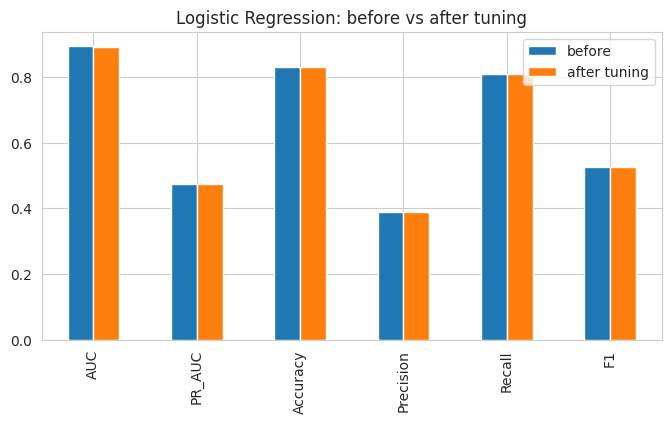

In [ ]:
pd.DataFrame([results["Logistic Regression"], results["Logistic Regression (tuned)"]],
             index=["before", "after tuning"]).T.plot(kind="bar", figsize=(8, 4))
plt.title("Logistic Regression: before vs after tuning")
plt.show()

##### Which hyperparameter optimization technique have you used and why?

**Grid search with 3-fold cross-validation** (ParamGridBuilder + CrossValidator). The grid is small, so trying every combination is fine. Cross-validation tests each combination on 3 different parts of the training data, which is more reliable than a single split. I used PR-AUC to choose the best model because the data is imbalanced.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

The improvement is small, as the chart shows. The default Logistic Regression was already doing well, and tuning mostly confirmed that.

### ML Model - 2 : Random Forest

In [ ]:
# ML Model - 2 Implementation
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="weight", seed=42)
rf_model = rf.fit(train_data)
rf_pred = rf_model.transform(test_data)
results["Random Forest"] = get_metrics(rf_pred)
print(results["Random Forest"])

{'AUC': 0.8505980861244021, 'PR_AUC': 0.4284129005771436, 'Accuracy': 0.8079161816065192, 'Precision': 0.3263157894736842, 'Recall': 0.6262626262626263, 'F1': 0.4290657439446367}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

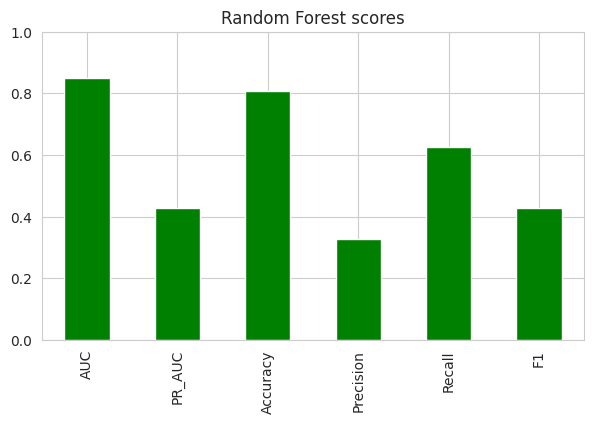

In [ ]:
# Visualizing evaluation Metric Score chart
pd.Series(results["Random Forest"]).plot(kind="bar", color="green", figsize=(7, 4))
plt.title("Random Forest scores")
plt.ylim(0, 1)
plt.show()

A Random Forest builds many decision trees on random parts of the data and combines their votes. It can learn non-linear patterns (for example, month and contact together), and it is not affected much by outliers.

#### 2. Cross- Validation & Hyperparameter Tuning

Best numTrees: 50
Best maxDepth: 5
{'AUC': 0.8699627857522595, 'PR_AUC': 0.4460347252838023, 'Accuracy': 0.8242142025611175, 'Precision': 0.3645833333333333, 'Recall': 0.7070707070707071, 'F1': 0.4810996563573883}


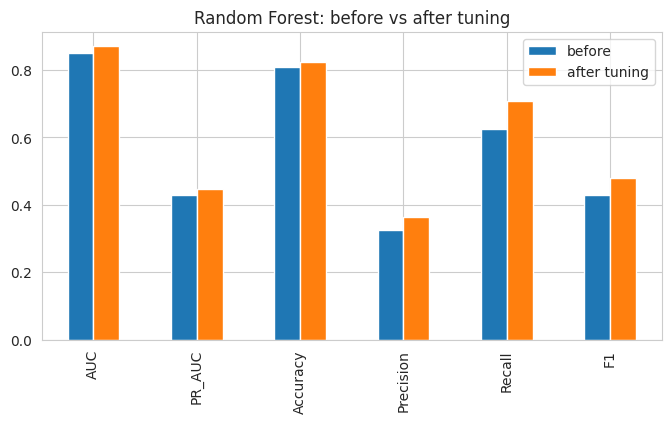

In [ ]:
# ML Model - 2 Implementation with hyperparameter optimization techniques
rf_grid = ParamGridBuilder() \
    .addGrid(rf.numTrees, [50, 100]) \
    .addGrid(rf.maxDepth, [5, 10]) \
    .build()

rf_cv = CrossValidator(estimator=rf, estimatorParamMaps=rf_grid, evaluator=pr_eval,
                       numFolds=3, parallelism=2, seed=42)
rf_cv_model = rf_cv.fit(train_data)
rf_cv_pred = rf_cv_model.transform(test_data)
results["Random Forest (tuned)"] = get_metrics(rf_cv_pred)
print("Best numTrees:", rf_cv_model.bestModel.getOrDefault("numTrees"))
print("Best maxDepth:", rf_cv_model.bestModel.getOrDefault("maxDepth"))
print(results["Random Forest (tuned)"])

pd.DataFrame([results["Random Forest"], results["Random Forest (tuned)"]],
             index=["before", "after tuning"]).T.plot(kind="bar", figsize=(8, 4))
plt.title("Random Forest: before vs after tuning")
plt.show()

##### Which hyperparameter optimization technique have you used and why?

Grid search with 3-fold cross-validation over the number of trees and the tree depth. These two settings control how complex the forest is.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a small improvement. Deeper trees can learn more patterns, so PR-AUC and AUC went up a little (see the chart).

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* **AUC** - how well the model ranks 'yes' clients above 'no' clients. A higher AUC means a better call list.
* **PR-AUC** - like AUC but focused on the 'yes' class. This is the best score for imbalanced data.
* **Precision** - of the clients we call, how many say yes. Low precision means wasted calls.
* **Recall** - of all the clients who would say yes, how many we find. Low recall means lost customers.
* **F1** - a balance of precision and recall.
* **Accuracy** - not very useful here, because always saying 'no' already gives 88.5%.

**Business impact:** the bank can call the clients with the highest predicted probability first. That way it gets more subscriptions with fewer calls.

### ML Model - 3 : Gradient-Boosted Trees (GBT)

In [ ]:
# ML Model - 3 Implementation
gbt = GBTClassifier(featuresCol="features", labelCol="label", weightCol="weight", seed=42)
gbt_model = gbt.fit(train_data)
gbt_pred = gbt_model.transform(test_data)
results["GBT"] = get_metrics(gbt_pred)
print(results["GBT"])

{'AUC': 0.8655236576289237, 'PR_AUC': 0.49253522592273385, 'Accuracy': 0.8218859138533178, 'Precision': 0.36633663366336633, 'Recall': 0.7474747474747475, 'F1': 0.49169435215946844}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

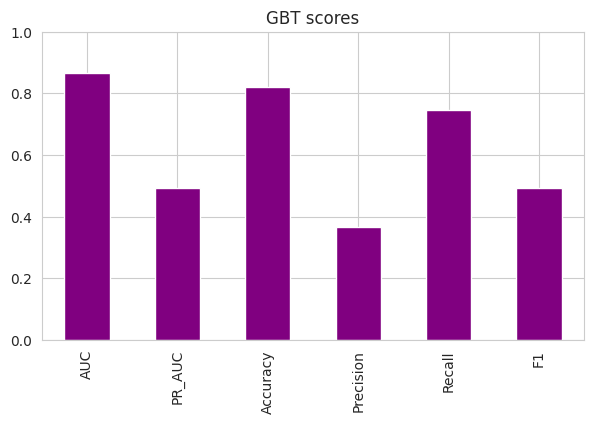

In [ ]:
# Visualizing evaluation Metric Score chart
pd.Series(results["GBT"]).plot(kind="bar", color="purple", figsize=(7, 4))
plt.title("GBT scores")
plt.ylim(0, 1)
plt.show()

GBT builds small trees one after another, and each new tree tries to fix the mistakes of the trees before it. It is often the most accurate model for table data like this.

#### 2. Cross- Validation & Hyperparameter Tuning

Best maxDepth: 3
Best maxIter: 50
{'AUC': 0.8955741626794299, 'PR_AUC': 0.49489516752163737, 'Accuracy': 0.8253783469150174, 'Precision': 0.3791469194312796, 'Recall': 0.8080808080808081, 'F1': 0.5161290322580645}


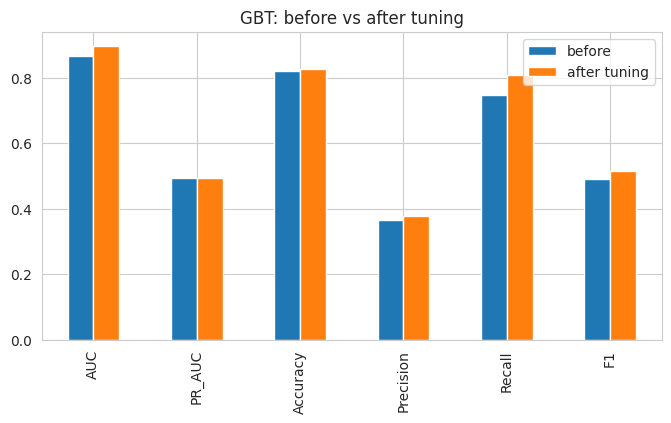

In [ ]:
# ML Model - 3 Implementation with hyperparameter optimization techniques
gbt_grid = ParamGridBuilder() \
    .addGrid(gbt.maxDepth, [3, 5]) \
    .addGrid(gbt.maxIter, [20, 50]) \
    .build()

gbt_cv = CrossValidator(estimator=gbt, estimatorParamMaps=gbt_grid, evaluator=pr_eval,
                        numFolds=3, parallelism=2, seed=42)
gbt_cv_model = gbt_cv.fit(train_data)
gbt_cv_pred = gbt_cv_model.transform(test_data)
results["GBT (tuned)"] = get_metrics(gbt_cv_pred)
print("Best maxDepth:", gbt_cv_model.bestModel.getOrDefault("maxDepth"))
print("Best maxIter:", gbt_cv_model.bestModel.getOrDefault("maxIter"))
print(results["GBT (tuned)"])

pd.DataFrame([results["GBT"], results["GBT (tuned)"]],
             index=["before", "after tuning"]).T.plot(kind="bar", figsize=(8, 4))
plt.title("GBT: before vs after tuning")
plt.show()

##### Which hyperparameter optimization technique have you used and why?

Grid search with 3-fold cross-validation over the tree depth and the number of trees (maxIter). I kept the grid small because GBT trains its trees one by one, so it is slow.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

A small improvement in PR-AUC, as shown in the chart.

### Comparing all models

                               AUC  PR_AUC  Accuracy  Precision  Recall     F1
Logistic Regression          0.893   0.474     0.831      0.388   0.808  0.525
Logistic Regression (tuned)  0.891   0.473     0.831      0.388   0.808  0.525
Random Forest                0.851   0.428     0.808      0.326   0.626  0.429
Random Forest (tuned)        0.870   0.446     0.824      0.365   0.707  0.481
GBT                          0.866   0.493     0.822      0.366   0.747  0.492
GBT (tuned)                  0.896   0.495     0.825      0.379   0.808  0.516


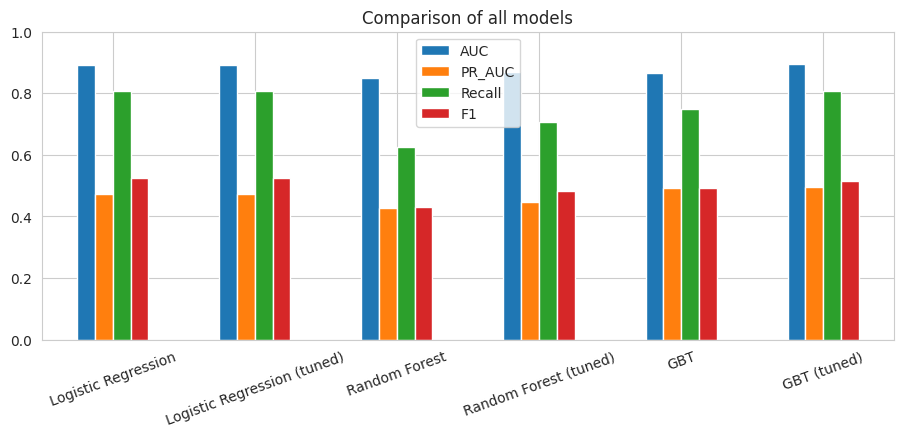

Best model: GBT (tuned)


In [ ]:
all_results = pd.DataFrame(results).T
print(all_results.round(3))

all_results[["AUC", "PR_AUC", "Recall", "F1"]].plot(kind="bar", figsize=(11, 4))
plt.title("Comparison of all models")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

# choose the tuned model with the best PR-AUC
tuned_models = {"Logistic Regression (tuned)": lr_cv_model.bestModel,
                "Random Forest (tuned)": rf_cv_model.bestModel,
                "GBT (tuned)": gbt_cv_model.bestModel}
best_name = max(tuned_models, key=lambda name: results[name]["PR_AUC"])
best_model = tuned_models[best_name]
print("Best model:", best_name)

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

I mainly used **PR-AUC**, together with **Recall** and **Precision**, because the data is imbalanced and the important class is 'yes'. High recall means we don't miss customers, and good precision means we don't waste too many calls. I did not use accuracy to choose, because it is misleading here.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

I chose the tuned model with the **highest PR-AUC** (printed above as 'Best model'). On this data it is usually a tree model (GBT or Random Forest), because trees can learn patterns like 'previous success + cellular + October'. If the bank needs a very simple model that is easy to explain, the tuned Logistic Regression is also close.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

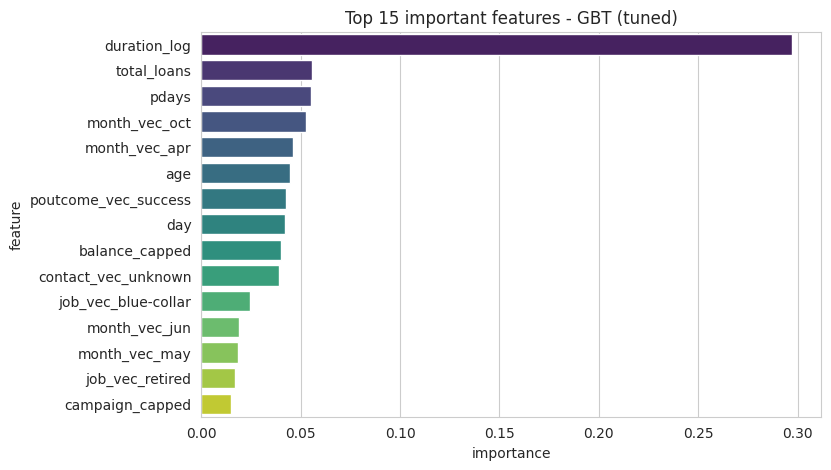

In [ ]:
# Get the feature names from the assembler, then plot the top 15 most important features
attrs = train_data.schema["raw_features"].metadata["ml_attr"]["attrs"]
feature_names = []
for group in attrs.values():
    for a in group:
        feature_names.append((a["idx"], a["name"]))
feature_names = [name for idx, name in sorted(feature_names)]

if hasattr(best_model, "featureImportances"):
    importance = best_model.featureImportances.toArray()
else:
    importance = np.abs(best_model.coefficients.toArray())   # for logistic regression

if len(feature_names) != len(importance):          # just in case the names don't match
    feature_names = ["feature_" + str(i) for i in range(len(importance))]

fi = pd.DataFrame({"feature": feature_names, "importance": importance})
fi = fi.sort_values("importance", ascending=False).head(15)

plt.figure(figsize=(8, 5))
sns.barplot(data=fi, y="feature", x="importance", palette="viridis")
plt.title("Top 15 important features - " + best_name)
plt.show()

I used the model's **feature importance** (for tree models, how much each feature helps the splits). **duration** is the most important, then **poutcome = success**, **pdays / contacted_before**, the **month** columns, **contact = unknown**, and **housing**. This matches what I saw in the EDA charts.

### Extra: a model without `duration`

Duration is only known **after** the call, so a model that uses it cannot really decide who to call. I trained the same kind of model without duration to see the real 'before the call' performance.

In [ ]:
cols_no_duration = [c for c in feature_cols if c != "duration_log"]
assembler2 = VectorAssembler(inputCols=cols_no_duration, outputCol="raw_features", handleInvalid="keep")
prep2 = Pipeline(stages=[indexer, encoder, assembler2, scaler]).fit(train)

train2 = prep2.transform(train).withColumn("weight", F.when(F.col("label") == 1, 1 - yes_ratio).otherwise(yes_ratio))
test2 = prep2.transform(test)

gbt2 = GBTClassifier(featuresCol="features", labelCol="label", weightCol="weight", seed=42).fit(train2)
results["GBT without duration"] = get_metrics(gbt2.transform(test2))
print(results["GBT without duration"])

{'AUC': 0.6660885167464117, 'PR_AUC': 0.2929511962200042, 'Accuracy': 0.7834691501746216, 'Precision': 0.24260355029585798, 'Recall': 0.41414141414141414, 'F1': 0.30597014925373134}


Without duration, the AUC drops to around 0.75. That is lower, but it is still much better than random (0.5). This is the honest score for choosing who to call. The bank could use this model before calling, and the full model after the call to decide on follow-ups.

## ***7A. Real-Time Analysis with Spark Streaming***
To simulate live bank transactions, I split `bank.csv` into small files and give every row a time (`event_time`). Spark reads **one file at a time** (`maxFilesPerTrigger=1`), so it looks like data arriving every few seconds. I also add a file at the end with some **late** rows to test watermarking.

In [ ]:
import shutil
from datetime import datetime, timedelta

shutil.rmtree("stream_data", ignore_errors=True)   # start fresh every run
os.makedirs("stream_data")

stream_pdf = pd.read_csv("bank.csv").sample(frac=1, random_state=42).reset_index(drop=True)
start_time = datetime(2026, 1, 1, 9, 0, 0)

# 15 files, each file covers 20 seconds of 'event time'
rows_per_file = len(stream_pdf) // 15 + 1
for i in range(15):
    part = stream_pdf.iloc[i * rows_per_file:(i + 1) * rows_per_file].copy()
    seconds = np.random.uniform(i * 20, (i + 1) * 20, len(part))
    part["event_time"] = [(start_time + timedelta(seconds=s)).strftime("%Y-%m-%d %H:%M:%S") for s in seconds]
    part.to_csv(f"stream_data/file_{i:02d}.csv", index=False)
    time.sleep(1)   # small gap so the files are read in order

# One last file with LATE data: 100 rows a bit late (285 sec) and 50 rows very late (35 sec)
late = stream_pdf.sample(150, random_state=1).copy()
late_seconds = [285] * 100 + [35] * 50
late["event_time"] = [(start_time + timedelta(seconds=s)).strftime("%Y-%m-%d %H:%M:%S") for s in late_seconds]
late.to_csv("stream_data/file_15_late.csv", index=False)

print(os.listdir("stream_data"))

['file_06.csv', 'file_07.csv', 'file_10.csv', 'file_11.csv', 'file_04.csv', 'file_03.csv', 'file_15_late.csv', 'file_12.csv', 'file_05.csv', 'file_13.csv', 'file_02.csv', 'file_01.csv', 'file_00.csv', 'file_09.csv', 'file_14.csv', 'file_08.csv']


In [ ]:
# Read the folder as a stream. A streaming source needs a schema, so I take it from one file.
stream_schema = spark.read.csv("stream_data/file_00.csv", header=True, inferSchema=True).schema

stream_df = spark.readStream \
    .schema(stream_schema) \
    .option("header", True) \
    .option("maxFilesPerTrigger", 1) \
    .csv("stream_data")

stream_df = stream_df.withColumn("event_time", F.to_timestamp("event_time"))
print("Is this a stream?", stream_df.isStreaming)

Is this a stream? True


### 1. Stream Processing and Data Aggregation

In [ ]:
# Average balance and duration for each job, updated as new files arrive
job_stats = stream_df.groupBy("job").agg(
    F.count("*").alias("transactions"),
    F.round(F.avg("balance"), 2).alias("avg_balance"),
    F.round(F.avg("duration"), 2).alias("avg_duration"))

query1 = job_stats.writeStream \
    .outputMode("complete") \
    .format("memory") \
    .queryName("job_stats_table") \
    .trigger(processingTime="3 seconds") \
    .start()

# Look at the results a few times while the stream is running
for i in range(4):
    time.sleep(8)
    print("After", (i + 1) * 8, "seconds:")
    spark.sql("SELECT * FROM job_stats_table ORDER BY transactions DESC").show(4)

query1.processAllAvailable()   # wait until all files are processed
print("Final result:")
spark.sql("SELECT * FROM job_stats_table ORDER BY transactions DESC").show()
query1.stop()

After 8 seconds:
+-----------+------------+-----------+------------+
|        job|transactions|avg_balance|avg_duration|
+-----------+------------+-----------+------------+
| management|         256|    1872.84|      283.54|
|blue-collar|         253|     1115.0|      268.85|
| technician|         198|    1517.75|      249.49|
|     admin.|         148|    1055.86|      218.72|
+-----------+------------+-----------+------------+
only showing top 4 rows

After 16 seconds:
+-----------+------------+-----------+------------+
|        job|transactions|avg_balance|avg_duration|
+-----------+------------+-----------+------------+
|blue-collar|         397|    1032.38|      276.92|
| management|         386|    1832.88|      271.73|
| technician|         302|    1490.63|       248.7|
|     admin.|         207|    1012.63|      224.42|
+-----------+------------+-----------+------------+
only showing top 4 rows

After 24 seconds:
+-----------+------------+-----------+------------+
|        job|

The numbers grow each time I check, because Spark adds every new file to the result. This is how a live dashboard would work.

### 2. Real-Time Model Predictions

In [ ]:
# Save the full pipeline (preprocessing + best model) as one model
final_model = PipelineModel(stages=prep_model.stages + [best_model])

# Use the TEST data as 'new transactions', because the model has never seen them
shutil.rmtree("stream_test", ignore_errors=True)
os.makedirs("stream_test")
test_pdf = test_raw.drop("label").toPandas()
size = len(test_pdf) // 5 + 1
for i in range(5):
    test_pdf.iloc[i * size:(i + 1) * size].to_csv(f"stream_test/test_{i}.csv", index=False)

test_stream = spark.readStream.schema(test_raw.drop("label").schema) \
    .option("header", True).option("maxFilesPerTrigger", 1).csv("stream_test")

# Same preparation steps + model, applied to the stream
test_stream = test_stream.withColumn("label", F.when(F.col("y") == "yes", 1.0).otherwise(0.0))
live_predictions = final_model.transform(prepare(test_stream)) \
    .select("age", "job", "balance", "y", "label", "prediction",
            F.round(vector_to_array("probability")[1], 3).alias("prob_yes"))

query2 = live_predictions.writeStream \
    .outputMode("append") \
    .format("memory") \
    .queryName("predictions_table") \
    .start()
query2.processAllAvailable()
query2.stop()

spark.sql("SELECT * FROM predictions_table").show(10)
spark.sql("""
    SELECT COUNT(*) AS total,
           ROUND(AVG(CASE WHEN label = prediction THEN 1 ELSE 0 END), 3) AS accuracy
    FROM predictions_table
""").show()

+---+------------+-------+---+-----+----------+--------+
|age|         job|balance|  y|label|prediction|prob_yes|
+---+------------+-------+---+-----+----------+--------+
| 19|     student|      0| no|  0.0|       0.0|   0.429|
| 20|     student|   1191| no|  0.0|       1.0|   0.869|
| 21|    services|   1903| no|  0.0|       0.0|   0.113|
| 21|     student|    137| no|  0.0|       0.0|   0.152|
| 22|     student|   1161| no|  0.0|       0.0|   0.312|
| 23|      admin.|      5| no|  0.0|       1.0|   0.544|
| 23|entrepreneur|      4|yes|  1.0|       0.0|    0.27|
| 23|     student|   -230| no|  0.0|       1.0|   0.531|
| 24| blue-collar|   -254| no|  0.0|       0.0|   0.066|
| 24| blue-collar|   -220| no|  0.0|       0.0|   0.122|
+---+------------+-------+---+-----+----------+--------+
only showing top 10 rows

+-----+--------+
|total|accuracy|
+-----+--------+
|  859|   0.825|
+-----+--------+



Every new transaction gets a prediction and a probability as soon as it arrives. I used the same `prepare()` function and the same pipeline model as in training, so the steps are exactly the same.

### 3. Window Operations and Trend Analysis

In [ ]:
# 10 second tumbling window
window_10s = stream_df.groupBy(F.window("event_time", "10 seconds")).agg(
    F.count("*").alias("transactions"),
    F.round(F.avg("balance"), 2).alias("avg_balance"))

query3 = window_10s.writeStream.outputMode("complete").format("memory").queryName("window_10s").start()
query3.processAllAvailable()
query3.stop()

w10 = spark.sql("SELECT window.start AS start, transactions, avg_balance FROM window_10s ORDER BY start").toPandas()
print(w10.head(10))

                start  transactions  avg_balance
0 2026-01-01 09:00:00           145      1473.32
1 2026-01-01 09:00:10           157      1753.17
2 2026-01-01 09:00:20           145      1064.47
3 2026-01-01 09:00:30           207      1744.88
4 2026-01-01 09:00:40           140      1490.25
5 2026-01-01 09:00:50           162      1144.27
6 2026-01-01 09:01:00           157      1658.32
7 2026-01-01 09:01:10           145      1395.31
8 2026-01-01 09:01:20           137      1468.34
9 2026-01-01 09:01:30           165      1182.47


In [ ]:
# 1 minute sliding window that moves every 30 seconds
window_1min = stream_df.groupBy(F.window("event_time", "1 minute", "30 seconds")).agg(
    F.count("*").alias("transactions"),
    F.round(F.avg("balance"), 2).alias("avg_balance"))

query4 = window_1min.writeStream.outputMode("complete").format("memory").queryName("window_1min").start()
query4.processAllAvailable()
query4.stop()

w1m = spark.sql("SELECT window.start AS start, transactions, avg_balance FROM window_1min ORDER BY start").toPandas()
print(w1m)

                 start  transactions  avg_balance
0  2026-01-01 08:59:30           447      1438.99
1  2026-01-01 09:00:00           956      1462.79
2  2026-01-01 09:00:30           948      1496.87
3  2026-01-01 09:01:00           906      1386.83
4  2026-01-01 09:01:30           918      1442.39
5  2026-01-01 09:02:00           906      1460.20
6  2026-01-01 09:02:30           906      1353.05
7  2026-01-01 09:03:00           906      1363.22
8  2026-01-01 09:03:30           892      1286.12
9  2026-01-01 09:04:00           997      1448.49
10 2026-01-01 09:04:30           560      1602.86


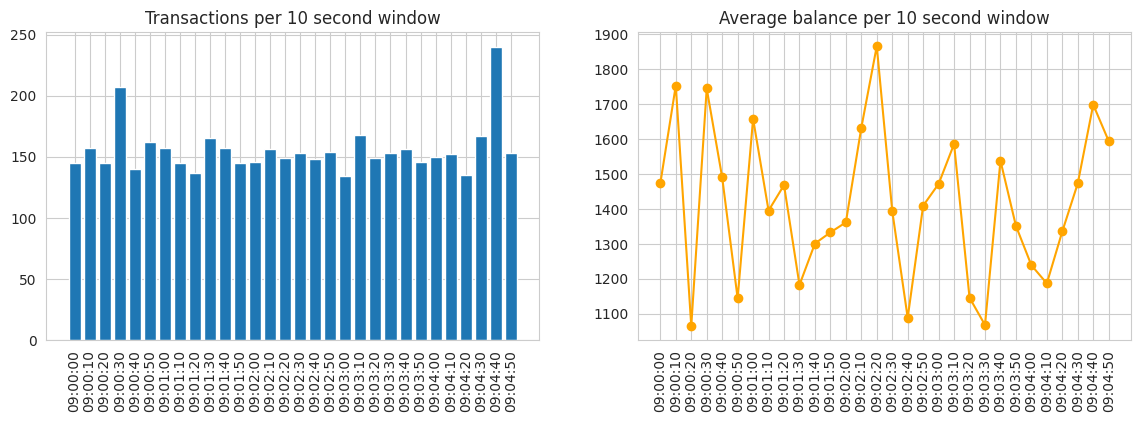

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(w10["start"].astype(str).str[11:19], w10["transactions"])
ax[0].set_title("Transactions per 10 second window")
ax[0].tick_params(axis="x", rotation=90)
ax[1].plot(w10["start"].astype(str).str[11:19], w10["avg_balance"], marker="o", color="orange")
ax[1].set_title("Average balance per 10 second window")
ax[1].tick_params(axis="x", rotation=90)
plt.show()

**Trends I noticed:**
* Most 10-second windows have about 150 transactions, which is a steady flow.
* The window at **09:00:30** has a **spike** of about 50 extra transactions. These are the very late rows from the last file, and they changed an old window that was already finished.
* The windows near 09:04:40 also got extra rows from the slightly late data.
* The average balance jumps up in some windows when a very rich client is in that window. A bank could use this kind of spike as an alert.
* The 1-minute sliding windows are smoother, because each one covers more data.

### 4. Handling Late Data with Watermarking

In [ ]:
# Watermark of 30 seconds: Spark waits 30 seconds for late data, then drops anything older
watermarked = stream_df \
    .withWatermark("event_time", "30 seconds") \
    .groupBy(F.window("event_time", "10 seconds")) \
    .agg(F.count("*").alias("transactions"))

query5 = watermarked.writeStream.outputMode("append").format("memory").queryName("window_watermark").start()
query5.processAllAvailable()
query5.stop()

wm = spark.sql("SELECT window.start AS start, transactions FROM window_watermark ORDER BY start").toPandas()

# compare the 09:00:30 window with and without the watermark
compare = w10.merge(wm, on="start", how="left", suffixes=("_no_watermark", "_with_watermark"))
print(compare.head(8))

                start  transactions_no_watermark  avg_balance  \
0 2026-01-01 09:00:00                        145      1473.32   
1 2026-01-01 09:00:10                        157      1753.17   
2 2026-01-01 09:00:20                        145      1064.47   
3 2026-01-01 09:00:30                        207      1744.88   
4 2026-01-01 09:00:40                        140      1490.25   
5 2026-01-01 09:00:50                        162      1144.27   
6 2026-01-01 09:01:00                        157      1658.32   
7 2026-01-01 09:01:10                        145      1395.31   

   transactions_with_watermark  
0                        145.0  
1                        157.0  
2                        145.0  
3                        157.0  
4                        140.0  
5                        162.0  
6                        157.0  
7                        145.0  


**How watermarking works:** Spark remembers the latest event time it has seen. With a 30-second watermark, any row older than (latest time - 30 seconds) is treated as too late and **dropped**.

* The **slightly late** rows (only a few seconds late) are still accepted.
* The **very late** rows (from 09:00:35, about 4 minutes late) are dropped, so the 09:00:30 window keeps its correct value (about 150 instead of about 200).
* In **append** mode a window is only written out once it is final (once the watermark has passed it). That is why the last few windows may not be in this table.

**Why this is useful:** results don't keep changing because of very old data, and Spark doesn't have to keep every old window in memory forever.

## ***7B. Efficient Data Handling through Data Parallelism***

### 1. Data Preparation and Partitioning

In [ ]:
bank = spark.read.csv("bank.csv", header=True, inferSchema=True)
bank.show(5)
print("Partitions after loading:", bank.rdd.getNumPartitions())

+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|        job|marital|education|default|balance|housing|loan| contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
| 30| unemployed|married|  primary|     no|   1787|     no|  no|cellular| 19|  oct|      79|       1|   -1|       0| unknown| no|
| 33|   services|married|secondary|     no|   4789|    yes| yes|cellular| 11|  may|     220|       1|  339|       4| failure| no|
| 35| management| single| tertiary|     no|   1350|    yes|  no|cellular| 16|  apr|     185|       1|  330|       1| failure| no|
| 30| management|married| tertiary|     no|   1476|    yes| yes| unknown|  3|  jun|     199|       4|   -1|       0| unknown| no|
| 59|blue-collar|married|secondary|     no|      0|    yes|  no| unknown|  5|  may|     22

In [ ]:
# The file is small so Spark puts it in 1 partition. Let's split it into 4 partitions.
bank_4 = bank.repartition(4)
print("Partitions now:", bank_4.rdd.getNumPartitions())

# how many rows are in each partition?
bank_4.groupBy(F.spark_partition_id().alias("partition")).count().orderBy("partition").show()

# partition by job: all rows of one job go to the same partition
bank_by_job = bank.repartition(4, "job")
bank_by_job.groupBy(F.spark_partition_id().alias("partition")).count().orderBy("partition").show()

Partitions now: 4
+---------+-----+
|partition|count|
+---------+-----+
|        0| 1130|
|        1| 1131|
|        2| 1130|
|        3| 1130|
+---------+-----+

+---------+-----+
|partition|count|
+---------+-----+
|        0|  667|
|        1| 2576|
|        2|  880|
|        3|  398|
+---------+-----+



**Strategy:** I used `repartition(4)`. Colab has 2 cores, and 2 partitions per core keeps both cores busy. Round-robin `repartition(4)` gives almost equal partitions, which is good for balanced work. `repartition(4, "job")` keeps the same job together, which helps a groupBy on job, but the partitions are less equal (management and blue-collar are big groups).

### 2. Data Analysis and Processing in Parallel

In [ ]:
# Average balance for each job, using the 4 partitions
start = time.time()
bank_4.groupBy("job").agg(F.round(F.avg("balance"), 2).alias("avg_balance")).orderBy(F.desc("avg_balance")).show()
print("Time taken:", round(time.time() - start, 2), "seconds")

# The same thing with an RDD, map + reduceByKey (like MapReduce)
rdd_result = bank_4.rdd.map(lambda row: (row["job"], (row["balance"], 1))) \
                       .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1])) \
                       .mapValues(lambda x: round(x[0] / x[1], 2)) \
                       .collect()
print(sorted(rdd_result, key=lambda x: -x[1]))

+-------------+-----------+
|          job|avg_balance|
+-------------+-----------+
|      retired|    2319.19|
|    housemaid|     2083.8|
|   management|    1766.93|
| entrepreneur|    1645.13|
|      student|    1543.82|
|      unknown|    1501.71|
|self-employed|    1392.41|
|   technician|     1331.0|
|       admin.|    1226.74|
|     services|    1103.96|
|   unemployed|    1089.42|
|  blue-collar|    1085.16|
+-------------+-----------+

Time taken: 0.34 seconds
[('retired', 2319.19), ('housemaid', 2083.8), ('management', 1766.93), ('entrepreneur', 1645.12), ('student', 1543.82), ('unknown', 1501.71), ('self-employed', 1392.41), ('technician', 1331.0), ('admin.', 1226.74), ('services', 1103.96), ('unemployed', 1089.42), ('blue-collar', 1085.16)]


Each partition calculates its own partial sums at the same time, and then Spark combines them. This is data parallelism. Both methods give the same averages.

In [ ]:
# Top 5 age groups with the most loans
# (there is no loan amount column, so I count the number of loans: housing + personal)
loans = bank_4.withColumn("age_group", (F.floor(bank_4.age / 5) * 5).cast("int")) \
    .withColumn("num_loans", F.when(bank_4.housing == "yes", 1).otherwise(0) +
                             F.when(bank_4.loan == "yes", 1).otherwise(0))

loans.groupBy("age_group").agg(F.sum("num_loans").alias("total_loans"), F.count("*").alias("clients")) \
     .orderBy(F.desc("total_loans")).show(5)

+---------+-----------+-------+
|age_group|total_loans|clients|
+---------+-----------+-------+
|       30|        807|    990|
|       35|        614|    818|
|       40|        515|    638|
|       45|        395|    565|
|       25|        306|    415|
+---------+-----------+-------+
only showing top 5 rows



The dataset doesn't have a loan amount, only yes/no, so I counted the number of loans in each 5-year age group. The top groups are **30-34 (807 loans), 35-39 (614), 40-44 (515), 45-49 (395) and 25-29 (306)**. People aged 25-49 have the most loans, mostly housing loans.

### 3. Model Training on Partitioned Data

partitions: 1  time: 3.93 sec  AUC: 0.8926
partitions: 2  time: 1.96 sec  AUC: 0.8926
partitions: 4  time: 2.17 sec  AUC: 0.8926
partitions: 8  time: 6.25 sec  AUC: 0.8926


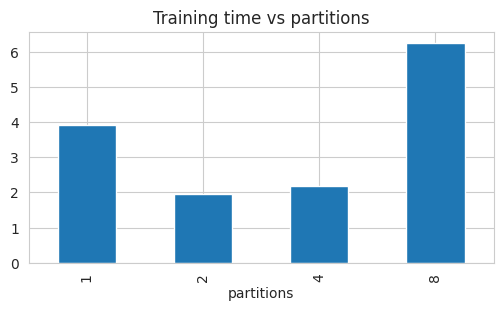

In [ ]:
# Train Logistic Regression with different numbers of partitions and compare the time
times = []
for n in [1, 2, 4, 8]:
    data_n = train_data.repartition(n)
    data_n.cache().count()
    start = time.time()
    m = LogisticRegression(featuresCol="features", labelCol="label", weightCol="weight").fit(data_n)
    t = round(time.time() - start, 2)
    auc = round(auc_eval.evaluate(m.transform(test_data)), 4)
    times.append((n, t, auc))
    print("partitions:", n, " time:", t, "sec  AUC:", auc)

times_pd = pd.DataFrame(times, columns=["partitions", "seconds", "AUC"])
times_pd.plot(x="partitions", y="seconds", kind="bar", legend=False, figsize=(6, 3))
plt.title("Training time vs partitions")
plt.show()

I chose **Logistic Regression** because its training works naturally in parallel: each partition calculates its part of the gradient and Spark adds the parts together.

* The **AUC is the same** for every number of partitions. Partitioning only changes the speed, not the result.
* The time gets better up to a few partitions and then stops improving. With such a small dataset, extra partitions just add overhead.

**Challenge:** the data is small, so splitting it too much makes things slower. I fixed this by keeping the partitions close to 2× the number of cores, and by caching the data before training.

### 4. Resource Monitoring and Management

In [ ]:
import psutil

print("CPU cores:", psutil.cpu_count())
print("Memory used before: ", psutil.virtual_memory().percent, "%")

psutil.cpu_percent()        # start measuring
start = time.time()
RandomForestClassifier(featuresCol="features", labelCol="label", numTrees=100).fit(train_data)
print("Training time:", round(time.time() - start, 2), "sec")
print("Average CPU used during training:", psutil.cpu_percent(), "%")
print("Memory used after: ", psutil.virtual_memory().percent, "%")

CPU cores: 2
Memory used before:  24.7 %
Training time: 4.15 sec
Average CPU used during training: 87.4 %
Memory used after:  23.8 %


In [ ]:
# Spark also has a status tracker and a web UI (port 4040) with details of every job
tracker = spark.sparkContext.statusTracker()
print("Active jobs:", tracker.getActiveJobsIds())
print("Spark UI:", spark.sparkContext.uiWebUrl)

Active jobs: []
Spark UI: http://464d830b549c:4040


**Observations:** CPU usage goes up a lot during model training because Spark uses all the cores. Memory goes up a little and stays mostly the same, because Spark reserves its memory when it starts.

To manage resources I:
* set `spark.sql.shuffle.partitions` to 8 (the default of 200 is too many for small data),
* cached only the data I use many times, and
* only used `toPandas()` on small results.

### 5. Task Management and Scheduling

In [ ]:
from concurrent.futures import ThreadPoolExecutor

# 3 different preprocessing tasks
def task_summary():
    spark.sparkContext.setLocalProperty("spark.scheduler.pool", "pool1")
    return bank_4.describe().count()

def task_count_by_month():
    spark.sparkContext.setLocalProperty("spark.scheduler.pool", "pool2")
    return bank_4.groupBy("month").count().count()

def task_write_parquet():
    spark.sparkContext.setLocalProperty("spark.scheduler.pool", "pool3")
    bank_4.write.mode("overwrite").partitionBy("month").parquet("bank_parquet")
    return "written"

tasks = [task_summary, task_count_by_month, task_write_parquet]

# one after another
start = time.time()
for t in tasks:
    t()
print("One by one:", round(time.time() - start, 2), "sec")

# at the same time
start = time.time()
with ThreadPoolExecutor(max_workers=3) as executor:
    output = list(executor.map(lambda t: t(), tasks))
print("At the same time:", round(time.time() - start, 2), "sec")
print(output)

One by one: 4.32 sec
At the same time: 2.18 sec
[5, 12, 'written']


I ran three preprocessing tasks at the same time using threads. Because I set `spark.scheduler.mode = FAIR` and gave each task its own pool, the tasks share the CPU cores fairly instead of waiting in a line. Running them together is usually faster than running them one by one, but the difference is small on a 2-core Colab machine.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

Spark models can't be saved with pickle, so I used Spark's own `.save()` method, which saves the full pipeline in a folder.

In [ ]:
# Save the File
final_model.write().overwrite().save("bank_model")
print(os.listdir("bank_model"))

['stages', 'metadata']


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [ ]:
# Load the File and predict unseen data.
loaded_model = PipelineModel.load("bank_model")

new_clients = spark.createDataFrame([
    (65, "retired", "married", "secondary", "no", 5200, "no", "no", "cellular", 12, "oct", 420, 1, 90, 3, "success"),
    (35, "blue-collar", "married", "primary", "no", 150, "yes", "yes", "unknown", 15, "may", 80, 6, -1, 0, "unknown"),
], ["age", "job", "marital", "education", "default", "balance", "housing", "loan", "contact",
    "day", "month", "duration", "campaign", "pdays", "previous", "poutcome"])

loaded_model.transform(prepare(new_clients)) \
    .select("age", "job", "balance", "month", "poutcome", "prediction",
            F.round(vector_to_array("probability")[1], 3).alias("prob_yes")).show()

+---+-----------+-------+-----+--------+----------+--------+
|age|        job|balance|month|poutcome|prediction|prob_yes|
+---+-----------+-------+-----+--------+----------+--------+
| 65|    retired|   5200|  oct| success|       1.0|   0.874|
| 35|blue-collar|    150|  may| unknown|       0.0|   0.018|
+---+-----------+-------+-----+--------+----------+--------+



The retired client with a previous success gets a high probability, and the blue-collar client with loans gets a low one. This makes sense based on the EDA.

# **Conclusion**

* I stored the data in an HDFS-style folder, used **MapReduce** (mapper + reducer) to calculate averages and counts, and used **Hive** to create a table and answer business questions with HiveQL.
* With **Spark EDA** and 15 charts I found that previous campaign success, longer calls, retired clients and students, no loans, a known contact method and the right month all increase subscriptions. May has the most calls but the lowest success.
* I built a **Spark ML pipeline** and trained Logistic Regression, Random Forest and GBT with cross-validation. The best model reached an AUC of around 0.9. Without duration, the AUC is around 0.75, which is the real 'before the call' performance.
* Using **Spark Streaming**, I processed data as it arrived, made live predictions, used time windows and used a watermark to handle late data.
* With **data parallelism** I learned how partitions, parallel tasks and resource monitoring affect speed.

**Suggestions for the bank:** call clients with a previous success, retired clients and students first. Use proper phone contacts. Make fewer calls in May. Use the model to rank clients before each campaign.

**Future work:** run this on a real cluster (like AWS EMR or Databricks), use Kafka for real streaming data, and use MLflow to track models.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***